# Projet RoadAnomaly – Exploration des données

On avance étape par étape : un petit bout de code à la fois, qu'on comprend avant de passer à la suite.

**Démarche CRISP-DM**



# Plan du notebook (démarche CRISP-DM)

## 1. Business Understanding
- Contexte, BO et DSO

## 2. Data Understanding (exploration)
- Étapes 1 à 5 : organisation du dataset et types de fichiers
- Étapes 6 et 7 : une photo, son masque et ses valeurs
- Étapes 8 et 9 : vérification, statistiques et graphiques sur les 60 images
- Étape 10 : vérification visuelle des masques
- Étape 12 : nombre et taille des obstacles (masques d'instances)

## 3. Data Preparation
- Étape 13 : conversion des masques en 0 / 1
- Étape 14 : choix de la taille de travail (pleine résolution 1280 × 720 conservée)
- Étape 15 : découpage en entraînement / validation / test (stratifié par catégorie)
- Étape 16 : chargement des images et des masques
- Étape 17 : normalisation et statistiques de standardisation
- Étape 18 : data augmentation (flip, luminosité, contraste) sur l'entraînement uniquement

## 4. Modeling
- Étapes 19 et 20 : générateur de batchs et modèle 1 (U-Net simplifié construit nous-mêmes) — chapitres CNN et ANN
- Étape 21 : entraînement du modèle 1 (perte BCE + Dice, Adam, early stopping) et courbes de loss — chapitres ANN et Hyperparamètres
- Étape 22 : petite grid search (learning rate, batch size) — chapitre Hyperparamètres
- Étapes 23 à 26 : les autres modèles, dans les mêmes conditions
  - modèle 2 : U-Net simplifié **sans** data augmentation (effet de l'augmentation)
  - modèle 3 : encodeur-décodeur sans raccourcis, type FCN (effet des raccourcis)
  - modèle 4 : U-Net avec encodeur ResNet50 pré-entraîné (transfer learning)
  - modèle 5 : DeepLabV3+ avec encodeur ResNet50 pré-entraîné (transfer learning, autre architecture)
- Étape 27 : comparaison des loss des 5 modèles

## 5. Evaluation
- DSO1 : précision, recall, F1, IoU et Dice par pixel sur le test, pour les 5 modèles
- DSO2 : recall selon la taille de l'obstacle (< 0,1 %, 0,1–1 %, 1–5 %, > 5 % de l'image)
- DSO3 (option) : accuracy / F1 par catégorie et matrice de confusion

## 6. Analyse des résultats
- Meilleurs et pires cas
- Fausses alertes et obstacles ratés
- Comparaison des modèles (raccourcis, augmentation, transfer learning, architecture)
- Forces, limites et améliorations (dont perspective RNN sur des vidéos)
- En option : XAI avec Grad-CAM, pour vérifier que le modèle détecte les obstacles pour les bonnes raisons

## 7. Conclusion

# 1. Business Understanding

**Contexte :** un véhicule autonome doit repérer les obstacles inattendus sur la route (animaux, cônes, pneus perdus, objets divers), même rares. Le dataset RoadAnomaly contient 60 photos de route 1280 × 720, chacune avec un masque qui indique, pixel par pixel, où se trouve l'obstacle.

**BO1 – Détecter et localiser les obstacles inattendus.**
- **DSO1 :** segmentation binaire : pour chaque pixel, le modèle répond 1 (obstacle) ou 0 (fond).
- Évaluation : precision, recall, F1, IoU et Dice sur le test.
- Pourquoi par pixel : par image, la réponse serait toujours « oui » (les 60 images contiennent un obstacle) ; la segmentation dit **où** est l'obstacle.

**BO2 – Détecter les obstacles lointains.**
- **DSO2 :** mesurer la détection selon la **taille** de l'obstacle (un obstacle lointain apparaît petit ; le dataset ne donne pas la distance).
- Groupes : < 0,1 %, 0,1–1 %, 1–5 %, > 5 % de l'image.
- Évaluation : recall par groupe de taille.

**Option  – Classer le type d'obstacle.**
- **DSO3 :** un CNN pré-entraîné prédit la catégorie de l'image (animals, cones, lost_tires, obstacles, vehicle).
- Limites : une seule étiquette par image (tirée du nom de fichier), et seulement 3 images pour lost_tires et pour vehicle.

# 2. Data Understanding

Objectif : comprendre ce que contiennent les données **avant** de les modifier. On répond à quatre questions, dans l'ordre :

1. Comment le dataset est-il organisé et combien d'images contient-il ?
2. À quoi ressemble une image et son masque ?
3. Que contient exactement un masque ?
4. Les images et les masques correspondent-ils bien ?


- **Contenu :** des images de dangers inhabituels sur la route (animaux, rochers, cônes, autres obstacles), pour tester la perception des véhicules autonomes dans des situations rares mais critiques.
- **Annotations :** étiquettes pixel par pixel, réalisées avec l'outil LabelGrab de l'EPFL.
- **Structure :**
  - `frame_list.json` : liste de toutes les images ;
  - `credits.txt` : sources des photos ;
  - `frames/<nom>.webp` : l'image ;
  - `frames/<nom>.labels/labels_semantic.png` : le masque (fond = 0, anomalie = 2) ;
  - `frames/<nom>.labels/labels_instance.png` : l'identifiant de chaque objet.
- **Mises en garde :** certains masques d'instances **manquent**, et certaines annotations ont été faites **à une autre résolution puis redimensionnées**. Ces deux points seront vérifiés à la question 4.






**Les modèles ne sont pas réentraînés :**  les cellules d'entraînement rechargent automatiquement les poids et les historiques sauvegardés 

In [1]:
%pip install tensorflow numpy pandas matplotlib pillow ipykernel

Note: you may need to restart the kernel to use updated packages.


### Étape 1 : définir les chemins du projet

- `DOSSIER_PROJET` : le dossier qui contient ce notebook (VS Code y lance Python).
- `DATA_DIR` : le dataset décompressé ; `DOSSIER_MODELES` : les poids et historiques des modèles.
- `REENTRAINER = False` : les cellules d'entraînement rechargent les résultats déjà sauvegardés au lieu de réentraîner. Mettre `True` seulement pour tout réentraîner (très long sans GPU).

In [2]:
import os

DOSSIER_PROJET = os.getcwd()
FICHIER_ZIP = os.path.join(DOSSIER_PROJET, 'RoadAnomaly.zip')
DATA_DIR = os.path.join(DOSSIER_PROJET, 'data', 'RoadAnomaly')
DOSSIER_MODELES = os.path.join(DOSSIER_PROJET, 'RoadAnomaly_modeles')
REENTRAINER = False

print("Dossier du projet :", DOSSIER_PROJET)
print("Zip du dataset trouvé :", os.path.exists(FICHIER_ZIP))
print("Dossier des modèles trouvé :", os.path.exists(DOSSIER_MODELES))

Dossier du projet : c:\Projet DeepLearning
Zip du dataset trouvé : True
Dossier des modèles trouvé : True


### Étape 1 bis : décompresser le dataset

- `zipfile` (bibliothèque de Python) décompresse le fichier `RoadAnomaly.zip` dans le dossier `data`.
- Si le dataset est déjà décompressé, la cellule ne refait rien.
- Le zip peut contenir directement les fichiers ou un dossier `RoadAnomaly` : la cellule vérifie où se trouve `frame_list.json`.

In [3]:
import zipfile

if not os.path.exists(os.path.join(DATA_DIR, 'frame_list.json')):
    with zipfile.ZipFile(FICHIER_ZIP) as z:
        z.extractall(os.path.join(DOSSIER_PROJET, 'data'))

if not os.path.exists(os.path.join(DATA_DIR, 'frame_list.json')):
    DATA_DIR = os.path.join(DATA_DIR, 'RoadAnomaly')

print("Dataset :", DATA_DIR)
print(os.listdir(DATA_DIR))

Dataset : c:\Projet DeepLearning\data\RoadAnomaly
['credits.txt', 'frames', 'frame_list.json', 'readme.md']


### Étape 2 : regarder ce qu'il y a dans le dossier principal

- `DATA_DIR` (défini à l'étape 1) garde le chemin du dataset, pour ne pas le réécrire à chaque fois.
- `os.listdir(...)` affiche la liste de ce qui se trouve dans ce dossier.

**Résultat attendu :** `readme.md`, `frame_list.json`, `credits.txt` et `frames`.
Si on voit seulement `RoadAnomaly`, c'est un dossier en double : l'étape 1 bis corrige normalement le chemin automatiquement.

In [4]:
print(os.listdir(DATA_DIR))

['credits.txt', 'frames', 'frame_list.json', 'readme.md']


### Étape 3 : combien d'images a-t-on ?

Le fichier `frame_list.json` contient la liste de toutes les images du dataset.

- `import json` charge l'outil qui lit les fichiers JSON (un format texte pour stocker des listes et des données).
- `os.path.join(DATA_DIR, 'frame_list.json')` construit le chemin complet du fichier.
- `json.load(f)` transforme le contenu du fichier en liste Python.

**Résultat attendu :** une soixantaine de noms du genre `animals01_....webp`. Le début du nom indique le type d'obstacle (animals, cones…).

In [5]:
import json

with open(os.path.join(DATA_DIR, 'frame_list.json')) as f:
    frame_list = json.load(f)

print("Type :", type(frame_list))
print("Nombre d'images :", len(frame_list))
print("Les 5 premières :", frame_list[:5])

Type : <class 'list'>
Nombre d'images : 60
Les 5 premières : ['animals01_Guiguinto_railway_station_Calves.webp', 'animals02_Zagori_On_the_road_to_Papigko.webp', 'animals03_Zebras_in_the_road.webp', 'animals04_17_animal_casualties_so_far_in_2006.webp', 'animals05_cows_near_Phonsavan_Laos.webp']


### Étape 4 : que contient le dossier `frames` ?

Pour chaque image, `frames` contient :
- **l'image** (`.webp`) ;
- **un sous-dossier du même nom** (`.labels/`) avec les annotations.

`sorted(...)` trie la liste par ordre alphabétique, pour que chaque image apparaisse juste à côté de son dossier `.labels`.

**Résultat attendu :** environ deux fois plus d'éléments que d'images, en alternance image / dossier `.labels`.

In [6]:
FRAMES_DIR = os.path.join(DATA_DIR, 'frames')

contenu = sorted(os.listdir(FRAMES_DIR))
print("Nombre d'éléments dans frames :", len(contenu))
print(contenu[:6])

Nombre d'éléments dans frames : 120
['animals01_Guiguinto_railway_station_Calves.labels', 'animals01_Guiguinto_railway_station_Calves.webp', 'animals02_Zagori_On_the_road_to_Papigko.labels', 'animals02_Zagori_On_the_road_to_Papigko.webp', 'animals03_Zebras_in_the_road.labels', 'animals03_Zebras_in_the_road.webp']


### Étape 5 : quels types de fichiers a-t-on, et combien de chaque ?

- `Counter` est un compteur : chaque fois qu'on lui donne une valeur, il ajoute 1 à son total pour cette valeur.
- `os.walk(DATA_DIR)` parcourt le dossier et **tous ses sous-dossiers**, un par un.
- `os.path.splitext(nom)[1]` récupère l'extension d'un fichier (pour `labels_semantic.png`, on obtient `.png`). `.lower()` met en minuscules pour que `.PNG` et `.png` soient comptés ensemble.
- `most_common()` affiche les extensions de la plus fréquente à la moins fréquente.



In [7]:
from collections import Counter

compteur = Counter()
for dossier, sous_dossiers, fichiers in os.walk(DATA_DIR):
    for nom in fichiers:
        extension = os.path.splitext(nom)[1].lower()
        compteur[extension] += 1

for extension, nombre in compteur.most_common():
    print(f"{extension or '(sans extension)'} : {nombre} fichiers")

.png : 367 fichiers
.npy : 201 fichiers
.webp : 60 fichiers
.json : 47 fichiers
.txt : 1 fichiers
.md : 1 fichiers


**Résultat attendu :**
- `.webp` : les images (une soixantaine) ;
- `.png` : les masques sémantiques et d'instances ;
- `.json`, `.txt`, `.md` : frame_list, credits, readme ;
- éventuellement d'autres extensions : les fichiers de l'éditeur LabelGrab mentionnés dans le readme.

### Étape 6 : afficher une photo et son masque côte à côte

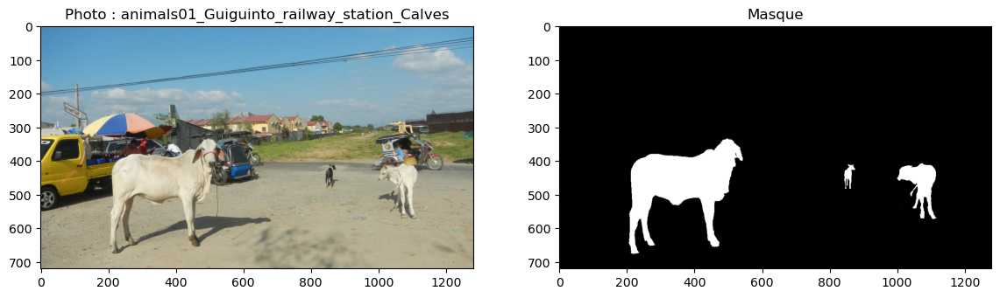

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

nom = os.path.splitext(frame_list[0])[0]
photo = Image.open(os.path.join(FRAMES_DIR, nom + '.webp'))
masque = Image.open(os.path.join(FRAMES_DIR, nom + '.labels', 'labels_semantic.png'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(photo)
axes[0].set_title('Photo : ' + nom)
axes[1].imshow(masque, cmap='gray')
axes[1].set_title('Masque')
plt.show()

### Étape 7 : regarder les valeurs des pixels du masque

In [9]:
masque_tab = np.array(masque)

print("Forme du masque :", masque_tab.shape)
print("Forme de la photo :", np.array(photo).shape)
print("Type des valeurs :", masque_tab.dtype)

valeurs, nombres = np.unique(masque_tab, return_counts=True)
for v, n in zip(valeurs, nombres):
    print(f"Valeur {v} : {n} pixels ({100 * n / masque_tab.size:.2f} %)")

Forme du masque : (720, 1280)
Forme de la photo : (720, 1280, 3)
Type des valeurs : uint8
Valeur 0 : 859783 pixels (93.29 %)
Valeur 2 : 61817 pixels (6.71 %)


Formes (720, 1280) et (720, 1280, 3) : le masque et la photo font tous les deux 720 pixels de haut sur 1280 de large.

Chaque pixel du masque correspond donc exactement au pixel de la photo au même endroit. Le 3 de la photo correspond aux trois couleurs.
Type uint8 : normal, ce sont des entiers de 0 à 255.
Seulement les valeurs 0 et 2 : pas de valeur inattendue, le masque est propre.
6,71 % de pixels à 2 : l’obstacle occupe environ 1/15 de l’image, contre 93,29 % de fond.

### Étape 8 : vérifier toutes les images

In [10]:
import pandas as pd

resultats = []
for fichier in frame_list:
    nom = os.path.splitext(fichier)[0]
    chemin_photo = os.path.join(FRAMES_DIR, nom + '.webp')
    chemin_masque = os.path.join(FRAMES_DIR, nom + '.labels', 'labels_semantic.png')
    chemin_instances = os.path.join(FRAMES_DIR, nom + '.labels', 'labels_instance.png')

    photo = np.array(Image.open(chemin_photo))
    masque = np.array(Image.open(chemin_masque))

    resultats.append({
        'nom': nom,
        'taille_photo': photo.shape[:2],
        'taille_masque': masque.shape[:2],
        'valeurs_masque': sorted(np.unique(masque).tolist()),
        'pct_anomalie': round(100 * (masque == 2).mean(), 2),
        'masque_instances': os.path.exists(chemin_instances),
    })

df = pd.DataFrame(resultats)
df

,nom,taille_photo,taille_masque,valeurs_masque,pct_anomalie,masque_instances
0,animals01_Guiguinto_railway_station_Calves,"(720, 1280)","(720, 1280)","[0, 2]",6.71,True
1,animals02_Zagori_On_the_road_to_Papigko,"(720, 1280)","(720, 1280)","[0, 2]",0.80,True
2,animals03_Zebras_in_the_road,"(720, 1280)","(720, 1280)","[0, 2]",23.37,True
3,animals04_17_animal_casualties_so_far_in_2006,"(720, 1280)","(720, 1280)","[0, 2]",6.60,True
4,animals05_cows_near_Phonsavan_Laos,"(720, 1280)","(720, 1280)","[0, 2]",14.61,True
5,animals06_sheep_roads_lambs,"(720, 1280)","(720, 1280)","[0, 2]",36.85,False
6,animals07_Aihole_Pattadakal,"(720, 1280)","(720, 1280)","[0, 2]",8.20,True
7,animals08_on_the_main_street_of_village_Lin_Al...,"(720, 1280)","(720, 1280)","[0, 2]",1.76,True
8,animals09_working_together,"(720, 1280)","(720, 1280)","[0, 2]",42.33,False
9,animals10_bovine_cattle_beside_road,"(720, 1280)","(720, 1280)","[0, 2]",2.77,True


#### Étape 9a : ajouter la catégorie de chaque image

In [11]:
df['categorie'] = df['nom'].str.replace(r'\d.*', '', regex=True)

print("Noms sans chiffre :", df.loc[~df['nom'].str.contains(r'\d'), 'nom'].tolist())
print("Catégories trouvées :", sorted(df['categorie'].unique()))

Noms sans chiffre : []
Catégories trouvées : ['animals', 'cones', 'lost_tires', 'obstacles', 'vehicle']


In [12]:
print("Nombre d'images :", len(df))
print("Photos dont le masque n'a pas la même taille :", (df['taille_photo'] != df['taille_masque']).sum())
print("Masques contenant d'autres valeurs que 0 et 2 :", (df['valeurs_masque'].astype(str) != '[0, 2]').sum())

Nombre d'images : 60
Photos dont le masque n'a pas la même taille : 0
Masques contenant d'autres valeurs que 0 et 2 : 0


60 images, toutes avec leur photo et leur masque.


Photos et masques ont la même taille : aucun redimensionnement correctif nécessaire.

Tous les masques ne contiennent que 0 et 2.

#### Étape 9c : nombre d’images par catégorie

In [13]:
df['categorie'].value_counts()

categorie
animals       31
obstacles     15
cones          8
lost_tires     3
vehicle        3
Name: count, dtype: int64

Catégories déséquilibrées : 31 animals sur 60 images.
Il faudra garder ces proportions dans chaque fold (stratification).

#### Étape 9d : masques d’instances

In [14]:
print("Avec masque d'instances :", df['masque_instances'].sum())
print("Sans masque d'instances :", (~df['masque_instances']).sum())
pd.crosstab(df['categorie'], df['masque_instances'])

Avec masque d'instances : 46
Sans masque d'instances : 14


masque_instances,False,True
categorie,,
animals,5,26
cones,2,6
lost_tires,0,3
obstacles,7,8
vehicle,0,3


46 images ont un masque d’instances, 14 n’en ont pas.

L’évaluation par objet se fera sur ces 46 images.

#### Étape 9e : taille des obstacles

In [ ]:
print("Moins de 1 % d'anomalie :", (df['pct_anomalie'] < 1).sum())
df['pct_anomalie'].describe().round(2)

Moins de 1 % d'anomalie : 6


count    60.00
mean      9.85
std      10.06
min       0.37
25%       1.80
50%       6.62
75%      13.79
max      42.33
Name: pct_anomalie, dtype: float64

#### Étape 9f : répartition du pourcentage d'anomalie
**Objectif :** voir si les obstacles occupent plutôt une petite ou une grande partie des images.

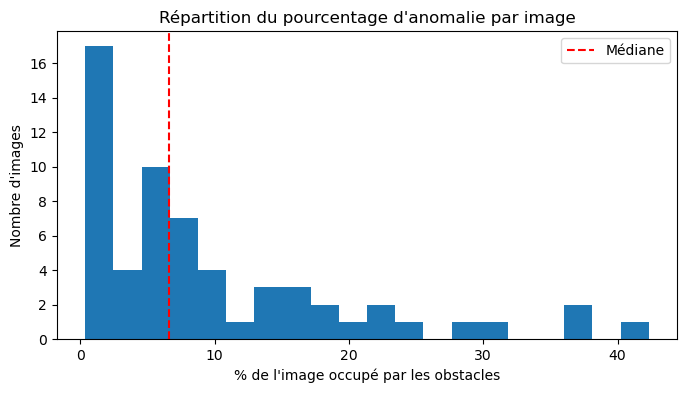

In [16]:
plt.figure(figsize=(8, 4))
plt.hist(df['pct_anomalie'], bins=20)
plt.axvline(df['pct_anomalie'].median(), color='red', linestyle='--', label='Médiane')
plt.title("Répartition du pourcentage d'anomalie par image")
plt.xlabel("% de l'image occupé par les obstacles")
plt.ylabel("Nombre d'images")
plt.legend()
plt.show()

### Étape 10 : vérifier visuellement les masques

**Objectif :** vérifier à l'œil que chaque masque est bien placé sur son obstacle.

**Pourquoi :**
- Les étapes 7 à 9 ont vérifié les masques avec des chiffres (taille, valeurs 0 et 2).
- Mais un masque peut avoir la bonne taille et les bonnes valeurs tout en étant mal dessiné : obstacle incomplet, débordement sur la route.
- Le masque est le corrigé que le modèle va apprendre : s'il est faux, le modèle apprend des erreurs.

**Méthode :**
- 10a : dans chaque catégorie, choisir l'image avec le plus petit obstacle et celle avec le plus grand (10 images).
- 10b : afficher ces 10 photos avec l'obstacle colorié en rouge.

**Ce qu'on cherche :** le rouge doit recouvrir exactement l'obstacle, sans déborder, aussi bien pour les petits que pour les grands obstacles.

#### Étape 10a : choisir le plus petit et le plus grand obstacle de chaque catégorie
**Objectif :** obtenir 10 images couvrant à la fois les 5 types d'obstacles et les tailles extrêmes.

In [17]:
plus_petits = df.loc[df.groupby('categorie')['pct_anomalie'].idxmin()]
plus_grands = df.loc[df.groupby('categorie')['pct_anomalie'].idxmax()]

exemples = pd.concat([plus_petits, plus_grands]).sort_values(['categorie', 'pct_anomalie'])
exemples[['nom', 'categorie', 'pct_anomalie']]

,nom,categorie,pct_anomalie
1,animals02_Zagori_On_the_road_to_Papigko,animals,0.80
8,animals09_working_together,animals,42.33
35,cones05_Corner_of_Kingsley_Park,cones,1.10
32,cones02_Broadmoor_Manhole_Cones,cones,6.56
40,lost_tires08,lost_tires,0.37
41,lost_tires09,lost_tires,0.99
53,obstacles12_rocks2,obstacles,0.63
48,obstacles07_czech_hedgehog,obstacles,24.68
59,vehicle03_Fuhrwerke_in_China,vehicle,7.68
57,vehicle01_man_carrying_dry_grass_on_bicycle,vehicle,12.95


On obtient bien 5 noms, un par catégorie
Chaque nom est la première image de sa catégorie dans le tableau.
L’échantillon mélange petits et grands obstacles, de 0,70 % (lost_tires03) à 16,46 % (obstacles01_boulder) de l’image. C’est un bon échantillon pour la vérification visuelle de l’étape 10b.

#### Étape 10b : afficher les 10 photos avec l'obstacle en rouge
**Objectif :** voir si la zone rouge du masque tombe exactement sur l'obstacle, pour les petits comme pour les grands obstacles.

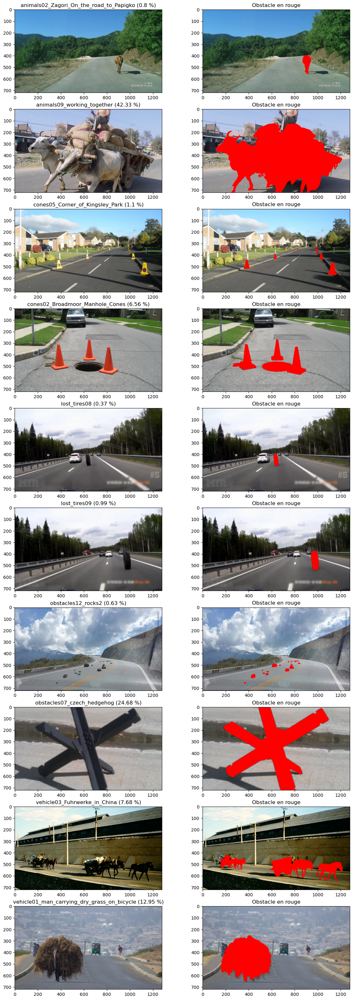

In [18]:
noms = exemples['nom'].tolist()
fig, axes = plt.subplots(len(noms), 2, figsize=(14, 4 * len(noms)))

for i, nom in enumerate(noms):
    photo = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.webp')))
    masque = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.labels', 'labels_semantic.png')))

    superposition = photo.copy()
    superposition[masque == 2] = [255, 0, 0]

    axes[i, 0].imshow(photo)
    axes[i, 0].set_title(f"{nom} ({exemples['pct_anomalie'].iloc[i]} %)")
    axes[i, 1].imshow(superposition)
    axes[i, 1].set_title('Obstacle en rouge')

plt.show()

### Étape 11 : visualiser les statistiques du dataset

**Objectif :** représenter en graphiques la répartition des catégories et des tailles d'obstacles.

**Pourquoi :**
- Les étapes 9c et 9e ont donné ces informations sous forme de chiffres.
- Un graphique les rend lisibles immédiatement, aussi pour quelqu'un qui ne connaît pas le projet.
- Ces graphiques serviront dans le rapport pour décrire le dataset.

**Méthode :**
- 11a : diagramme en barres du nombre d'images par catégorie.
- 11b : histogramme du pourcentage d'anomalie par image.

**Ce qu'on cherche :** voir si certaines catégories dominent, et si les obstacles sont plutôt petits ou plutôt grands.

#### Étape 11a : nombre d'images par catégorie
**Objectif :** voir d'un coup d'œil si les catégories sont équilibrées.

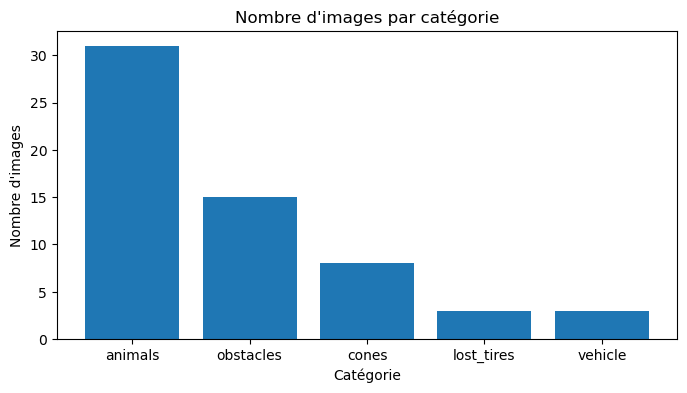

In [19]:
compte = df['categorie'].value_counts()

plt.figure(figsize=(8, 4))
plt.bar(compte.index, compte.values)
plt.title("Nombre d'images par catégorie")
plt.xlabel('Catégorie')
plt.ylabel("Nombre d'images")
plt.show()

### Étape 12 : les obstacles un par un (masques d'instances)

**Objectif :** compter les obstacles de chaque image et mesurer la taille de chacun.

**Pourquoi :**
- Jusqu'ici, le pourcentage d'anomalie additionnait tous les obstacles d'une image (un troupeau = une seule valeur).
- Les objectifs DSO1.2 (détecter chaque obstacle) et DSO2.1 (détection selon la taille) ont besoin de connaître chaque obstacle séparément.
- C'est le masque d'instances qui sépare les obstacles, en donnant un numéro différent à chacun.

**Méthode :**
- 12a : ouvrir un masque d'instances et regarder ce qu'il contient.
- 12b : l'afficher à côté du masque sémantique pour voir la différence.

**Ce qu'on cherche :** comprendre comment les obstacles sont numérotés, avant de les compter sur toutes les images.

#### Étape 12a : regarder le contenu d'un masque d'instances
**Objectif :** savoir comment les obstacles sont numérotés dans ce fichier.

In [20]:
nom = 'animals01_Guiguinto_railway_station_Calves'
instances = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.labels', 'labels_instance.png')))

print("Forme :", instances.shape)
print("Type :", instances.dtype)
print("Valeurs différentes :", np.unique(instances))

Forme : (720, 1280)
Type : uint8
Valeurs différentes : [0 1 2 3]


0 w 1 2 w3 kol wahda andha valeur mtaa pixel ( grayscale) w baad kol wahda nchedou ahna nlawnouha b loun awdhah


cmap='tab20' : applique une palette de couleurs pour rendre les différentes valeurs plus faciles à distinguer.

#### Étape 12b : comparer masque sémantique et masque d'instances
**Objectif :** voir concrètement la différence entre les deux masques sur la même image.

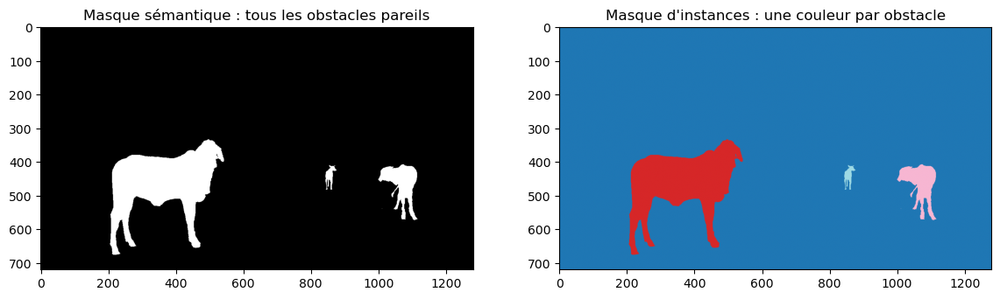

In [21]:
semantique = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.labels', 'labels_semantic.png')))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(semantique, cmap='gray')
axes[0].set_title('Masque sémantique : tous les obstacles pareils')
axes[1].imshow(instances, cmap='tab20')
axes[1].set_title("Masque d'instances : une couleur par obstacle")
plt.show()

#### Étape 12c : vérifier que les deux masques désignent les mêmes pixels
**Objectif :** vérifier que les pixels numérotés dans le masque d'instances sont bien les pixels « obstacle » du masque sémantique.
**Pourquoi :** si les deux masques ne coïncidaient pas, les obstacles comptés un par un ne correspondraient pas aux obstacles annotés.

In [22]:
print("Pixels obstacle (masque sémantique) :", (semantique == 2).sum())
print("Pixels obstacle (masque d'instances) :", (instances > 0).sum())
print("Pixels en désaccord :", ((semantique == 2) != (instances > 0)).sum())

Pixels obstacle (masque sémantique) : 61817
Pixels obstacle (masque d'instances) : 61817
Pixels en désaccord : 0


#### Étape 12d : lister tous les obstacles des 46 images
**Objectif :** construire un tableau avec une ligne par obstacle, et la part de l'image qu'il occupe.
**Pourquoi :** c'est ce tableau qui permettra de compter les obstacles et de les classer par taille (DSO2.1).

In [23]:
objets = []
for nom in df.loc[df['masque_instances'], 'nom']:
    instances = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.labels', 'labels_instance.png')))
    for numero in np.unique(instances):
        if numero == 0:
            continue
        pixels = (instances == numero).sum()
        objets.append({
            'nom': nom,
            'numero': int(numero),'pixels': int(pixels),
            'pct_image': round(100 * pixels / instances.size, 3),
        })

df_objets = pd.DataFrame(objets)
df_objets

,nom,numero,pixels,pct_image
0,animals01_Guiguinto_railway_station_Calves,1,51897,5.631
1,animals01_Guiguinto_railway_station_Calves,2,8805,0.955
2,animals01_Guiguinto_railway_station_Calves,3,1115,0.121
3,animals02_Zagori_On_the_road_to_Papigko,1,7365,0.799
4,animals03_Zebras_in_the_road,1,215418,23.374
...,...,...,...,...
196,vehicle02_Broadmoor_Cones_Skidloader,4,84740,9.195
197,vehicle03_Fuhrwerke_in_China,1,17874,1.939
198,vehicle03_Fuhrwerke_in_China,2,38459,4.173
199,vehicle03_Fuhrwerke_in_China,3,4828,0.524


Parce que l'objectif de cette étape est de compter les obstacles individuellement et de mesurer la taille de chacun  donccc l masque d instance ( chaque instance sa taille unique)

#### Étape 12e : combien d'obstacles par image ?
**Objectif :** compter le nombre total d'obstacles, et savoir combien d'images en contiennent un seul ou plusieurs.
**Pourquoi :** une image peut contenir un troupeau entier ; l'évaluation par objet (DSO1.2) doit retrouver chaque obstacle, pas seulement l'image.

In [24]:
nb_par_image = df_objets.groupby('nom').size()

print("Nombre total d'obstacles :", len(df_objets))
print("Images avec un seul obstacle :", (nb_par_image == 1).sum())
print("Images avec plusieurs obstacles :", (nb_par_image > 1).sum())
nb_par_image.describe().round(2)

Nombre total d'obstacles : 201
Images avec un seul obstacle : 18
Images avec plusieurs obstacles : 28


count    46.00
mean      4.37
std       5.37
min       1.00
25%       1.00
50%       3.00
75%       5.75
max      31.00
dtype: float64

| Statistique | Valeur | Signification |
|---|---:|---|
| count | 46 | Nombre d'images analysées |
| mean | 4,37 | Nombre moyen d'obstacles par image |
| std | 5,37 | Écart-type : forte variation du nombre d'obstacles |
| min | 1 | Minimum : 1 obstacle dans une image |
| 25% | 1 | 25 % des images ont au maximum 1 obstacle |
| 50% | 3 | Médiane : 50 % des images ont au maximum 3 obstacles |
| 75% | 5,75 | 75 % des images ont au maximum 5,75 obstacles |
| max | 31 | Maximum : 31 obstacles dans une image |

#### Étape 12f : classer les obstacles par taille
**Objectif :** répartir les obstacles dans les 4 groupes de taille de l'objectif DSO2.1.


**Pourquoi :** le DSO2.1 mesure la détection selon la taille de l'obstacle ; il faut savoir combien d'obstacles tombent dans chaque groupe.

In [25]:
df_objets['taille'] = pd.cut(df_objets['pct_image'],
                             bins=[0, 0.1, 1, 5, 100],
                             labels=['< 0,1 %', '0,1 – 1 %', '1 – 5 %', '> 5 %'],
                             right=False)
df_objets['taille'].value_counts().sort_index()

taille
< 0,1 %      63
0,1 – 1 %    70
1 – 5 %      49
> 5 %        19
Name: count, dtype: int64

| Groupe | Obstacles | Part du total | Ce que ça représente |
| --- | --- | --- | --- |
| < 0,1 % | 63 | 31 % | Moins de 920 pixels, soit un carré d'environ 30 × 30 pixels sur une image de 1280 × 720 |
| 0,1 – 1 % | 70 | 35 % | Petits obstacles |
| 1 – 5 % | 49 | 24 % | Obstacles moyens |
| > 5 % | 19 | 9 % | Grands obstacles, souvent proches de la caméra |

# 3. Data Preparation

**Objectif :** transformer les images et les masques pour qu'un modèle puisse apprendre dessus.

**Pourquoi :** l'exploration a montré plusieurs points à traiter avant l'entraînement :
- les masques valent 0 et 2, alors que le modèle attend 0 et 1 ;
- les images sont grandes (720 × 1280), mais les réduire trop ferait disparaître les petits obstacles ;
- les catégories sont déséquilibrées, il faut les répartir équitablement ;
- il n'y a que 60 images, d'où la data augmentation.

**Méthode :**
- Étape 13 : convertir les masques en 0 / 1.
- Étape 14 : choisir la taille de travail des images.
- Étape 15 : découper en entraînement, validation et test.
- Étape 16 : normaliser les images.
- Étape 17 : data augmentation.

### Étape 13 : convertir un masque en 0 / 1

**Objectif :** transformer les valeurs du masque (0 et 2) en 0 et 1.

**Pourquoi :**
- Le modèle donnera, pour chaque pixel, une probabilité entre 0 et 1 d'être un obstacle.
- Pour comparer sa réponse au masque, celui-ci doit utiliser la même échelle : 0 = fond, 1 = obstacle.
- La valeur 2 n'a pas de sens pour une probabilité.

**Ce qu'on cherche :** vérifier sur une image que la conversion garde exactement les mêmes pixels d'obstacle.

In [26]:
masque = np.array(Image.open(os.path.join(FRAMES_DIR, 'animals01_Guiguinto_railway_station_Calves.labels', 'labels_semantic.png')))
masque_binaire = (masque == 2).astype(np.uint8)

print("Valeurs avant :", np.unique(masque))
print("Valeurs après :", np.unique(masque_binaire))
print("Pixels obstacle avant :", (masque == 2).sum())
print("Pixels obstacle après :", (masque_binaire == 1).sum())

Valeurs avant : [0 2]
Valeurs après : [0 1]
Pixels obstacle avant : 61817
Pixels obstacle après : 61817


Les valeurs du masque passent de [0 2] à [0 1] : l’obstacle est maintenant codé 1.
Le nombre de pixels d’obstacle est identique avant et après (61 817) : aucun pixel n’a été perdu ni ajouté.
La conversion est validée sur une image ; elle sera appliquée à toutes les images au moment du redimensionnement.

### Étape 14 : choisir la taille de travail des images

**Objectif :** choisir à quelle taille redimensionner les images avant l'entraînement.

**Pourquoi :**
- Les images font 1280 × 720 pixels : les garder entières rendrait l'entraînement très lent et demanderait beaucoup de mémoire au GPU.
- Mais réduire une image réduit aussi ses obstacles : en divisant la largeur et la hauteur par 2, un obstacle perd les 3/4 de ses pixels.
- L'exploration a montré que deux tiers des obstacles occupent moins de 1 % de l'image : les plus petits risquent de disparaître.

**Méthode :** une **simulation**, qui ne modifie ni les images ni les données. Pour plusieurs tailles possibles, on calcule combien d'obstacles deviendraient minuscules (moins de 16 pixels, soit environ 4 × 4). Les variables portent le suffixe `_simulation` et sont supprimées à la fin, pour n'avoir aucun effet sur la suite.

**Ce qu'on cherche :** la plus petite taille qui garde la grande majorité des obstacles visibles.

In [27]:
tailles_simulation = {
    '1280 × 720 (origine)': 1,
    '960 × 540': 0.75,
    '640 × 360': 0.5,
    '320 × 180': 0.25,
}

for nom_taille_simulation, echelle_simulation in tailles_simulation.items():
    pixels_apres_simulation = df_objets['pixels'] * echelle_simulation ** 2
    nb_minuscules_simulation = (pixels_apres_simulation < 16).sum()
    print(f"{nom_taille_simulation} : {nb_minuscules_simulation} obstacles sur {len(df_objets)} feraient moins de 16 pixels")

del tailles_simulation, nom_taille_simulation, echelle_simulation, pixels_apres_simulation, nb_minuscules_simulation

1280 × 720 (origine) : 0 obstacles sur 201 feraient moins de 16 pixels
960 × 540 : 2 obstacles sur 201 feraient moins de 16 pixels
640 × 360 : 6 obstacles sur 201 feraient moins de 16 pixels
320 × 180 : 22 obstacles sur 201 feraient moins de 16 pixels


**Interprétation :**

| Taille | Pixels par image | Obstacles de moins de 16 pixels | Part des obstacles |
| --- | --- | --- | --- |
| 1280 × 720 | 921 600 (100 %) | 0 | 0 % |
| 960 × 540 | 518 400 (56 %) | 2 | 1 % |
| 640 × 360 | 230 400 (25 %) | 6 | 3 % |
| 320 × 180 | 57 600 (6 %) | 22 | 11 % |

**Conclusions :**
- À 640 × 360, seulement 6 obstacles sur 201 (3 %) deviennent minuscules.
- 960 × 540 n'en sauverait que 4 de plus, pour plus de deux fois plus de pixels à traiter.
- 320 × 180 ferait perdre 22 obstacles (11 %) : trop pour l'objectif sur les petits obstacles (DSO2.1).
- Taille retenue : 640 × 352 (352 au lieu de 360, pour des dimensions divisibles par 32, comme le demandent les CNN encodeur-décodeur).
- Piste non retenue : entraîner sur des morceaux d'image en pleine résolution (crops) ; le gain serait faible, car la perte à 640 × 352 n'est que de 3 %.

- Avec seulement 60 images, travailler en pleine résolution resterait possible, mais avec de très petits batchs ; la réduction n'est donc pas une obligation technique, mais un choix : chaque image est traitée des milliers de fois (epochs, grid search, 2 modèles) et occupe 4 fois moins de mémoire GPU à 640 × 352, pour seulement 3 % des obstacles perdus.

### Étape 15 : découper en entraînement, validation et test

**Objectif :** répartir les 60 images en trois ensembles : entraînement, validation et test.

**Pourquoi :**
- Entraînement : les images sur lesquelles le modèle apprend.
- Validation : des images que le modèle ne voit pas pendant l'apprentissage, pour choisir les hyperparamètres et arrêter l'entraînement au bon moment.
- Test : des images gardées de côté jusqu'à la fin, pour mesurer honnêtement la performance finale.
- Si on évaluait le modèle sur les images d'entraînement, il pourrait les avoir apprises par cœur : le score serait faussement bon.

**Méthode :**
- Environ 70 % entraînement, 15 % validation, 15 % test.
- Découpage stratifié : chaque catégorie est répartie séparément.
- Au moins 1 image de chaque catégorie en validation et en test, même pour les petites catégories (3 images).

**Ce qu'on cherche :** 3 ensembles qui contiennent toutes les catégories, dans des proportions proches.

In [28]:
import random
random.seed(42)

split = {}
for categorie, groupe in df.groupby('categorie'):
    noms = groupe['nom'].tolist()
    random.shuffle(noms)
    n_test = max(1, round(0.15 * len(noms)))
    n_val = max(1, round(0.15 * len(noms)))
    for nom in noms[:n_test]:
        split[nom] = 'test'
    for nom in noms[n_test:n_test + n_val]:
        split[nom] = 'validation'
    for nom in noms[n_test + n_val:]:
        split[nom] = 'entrainement'

df['ensemble'] = df['nom'].map(split)

In [29]:
pd.crosstab(df['categorie'], df['ensemble'], margins=True)

ensemble,entrainement,test,validation,All
categorie,,,,
animals,21,5,5,31
cones,6,1,1,8
lost_tires,1,1,1,3
obstacles,11,2,2,15
vehicle,1,1,1,3
All,40,10,10,60


### Étape 16 : préparer les images et les masques

**Objectif :** charger toutes les photos et tous les masques (convertis en 0 / 1), puis les répartir en entraînement, validation et test.

<span style="color: red;">

**Décision sur la taille :** on garde la résolution d'origine, 1280 × 720.

- La réduction à 640 × 352 a été étudiée (étapes 14 et 16a) : elle ferait perdre 6 obstacles minuscules sur 201.
- Avec seulement 60 images, la pleine résolution reste gérable sur le GPU de Colab, avec de petits batchs.
- C'est cohérent avec l'objectif DSO2.1, qui porte justement sur les petits obstacles.
- 720 et 1280 sont divisibles par 16 : un CNN encodeur-décodeur à 4 réductions de moitié fonctionne sans redimensionnement.

</span>

**Méthode :**
- 16a : hypothèse non appliquée, tester la réduction à 640 × 352 (variables supprimées ensuite).
- 16b : charger les 60 images en pleine résolution, avec les masques en 0 / 1.
- 16c : séparer les images selon le découpage de l'étape 15.

#### Étape 16a : tester sur une image

In [30]:
nom_reduit = 'animals01_Guiguinto_railway_station_Calves'
photo_reduit = Image.open(os.path.join(FRAMES_DIR, nom_reduit + '.webp')).convert('RGB')
masque_reduit = (np.array(Image.open(os.path.join(FRAMES_DIR, nom_reduit + '.labels', 'labels_semantic.png'))) == 2).astype(np.uint8)

photo_petite_reduit = np.array(photo_reduit.resize((640, 352), Image.BILINEAR))
masque_petit_reduit = np.array(Image.fromarray(masque_reduit).resize((640, 352), Image.NEAREST))

print("Photo réduite :", photo_petite_reduit.shape)
print("Masque réduit :", masque_petit_reduit.shape)
print("Valeurs du masque réduit :", np.unique(masque_petit_reduit))
print("Part d'obstacle avant :", round(100 * masque_reduit.mean(), 2), "%")
print("Part d'obstacle après :", round(100 * masque_petit_reduit.mean(), 2), "%")
print("Pixels obstacle avant :", masque_reduit.sum())
print("Pixels obstacle après :", masque_petit_reduit.sum())

del nom_reduit, photo_reduit, masque_reduit, photo_petite_reduit, masque_petit_reduit

Photo réduite : (352, 640, 3)
Masque réduit : (352, 640)
Valeurs du masque réduit : [0 1]
Part d'obstacle avant : 6.71 %
Part d'obstacle après : 6.71 %
Pixels obstacle avant : 61817
Pixels obstacle après : 15114


#### Étape 16b : charger les 60 images en pleine résolution

In [31]:
X, Y = [], []
for nom in df['nom']:
    photo = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.webp')).convert('RGB'))
    masque = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.labels', 'labels_semantic.png')))
    X.append(photo)
    Y.append((masque == 2).astype(np.uint8))

X = np.stack(X)
Y = np.stack(Y)
print("Photos :", X.shape)
print("Masques :", Y.shape)
print("Valeurs des masques :", np.unique(Y))

Photos : (60, 720, 1280, 3)
Masques : (60, 720, 1280)
Valeurs des masques : [0 1]


(60, 720, 1280) sans 4eme khater masque binaire 0 ou 1

#### Étape 16c : séparer en entraînement, validation et test
**Objectif :** ranger chaque image et son masque dans l'ensemble choisi à l'étape 15.

In [32]:
ensembles = df['ensemble'].values

X_train, Y_train = X[ensembles == 'entrainement'], Y[ensembles == 'entrainement']
X_val, Y_val = X[ensembles == 'validation'], Y[ensembles == 'validation']
X_test, Y_test = X[ensembles == 'test'], Y[ensembles == 'test']

print("Entraînement :", X_train.shape, Y_train.shape)
print("Validation :", X_val.shape, Y_val.shape)
print("Test :", X_test.shape, Y_test.shape)

Entraînement : (40, 720, 1280, 3) (40, 720, 1280)
Validation : (10, 720, 1280, 3) (10, 720, 1280)
Test : (10, 720, 1280, 3) (10, 720, 1280)


### Étape 17 : normaliser les images

**Objectif :** ramener les valeurs des pixels de 0 – 255 à une petite échelle, adaptée à l'apprentissage.

**Pourquoi :**
- Les réseaux de neurones apprennent mieux avec des valeurs petites et proches de 0 : les grands nombres rendent la rétropropagation instable.
- Les trois couleurs doivent être sur la même échelle, pour qu'aucune ne domine les autres.

**Méthode :**
- 17a : diviser les valeurs par 255, pour les ramener entre 0 et 1.
- 17b : calculer la moyenne et l'écart-type de chaque couleur, **sur l'entraînement uniquement**, pour la standardisation qui sera appliquée pendant l'entraînement.

**Ce qu'on cherche :** des images avec des valeurs entre 0 et 1, et les statistiques de normalisation de l'entraînement.

#### Étape 17a : ramener les pixels entre 0 et 1

In [33]:
X_train = X_train.astype(np.float32) / 255.0
X_val = X_val.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Minimum :", X_train.min(), "| Maximum :", X_train.max())
print("Type :", X_train.dtype)

Minimum : 0.0 | Maximum : 1.0
Type : float32


#### Étape 17b : statistiques de standardisation (entraînement uniquement)

In [34]:
moyenne = X_train.reshape(-1, 3).mean(axis=0)
ecart_type = X_train.reshape(-1, 3).std(axis=0)

print("Moyenne (rouge, vert, bleu) :", moyenne.round(3))
print("Écart-type (rouge, vert, bleu) :", ecart_type.round(3))

Moyenne (rouge, vert, bleu) : [0.455 0.455 0.455]
Écart-type (rouge, vert, bleu) : [0.224 0.22  0.239]


### Étape 18 : data augmentation

**Objectif :** créer des variantes des images d'entraînement, pour que le modèle voie plus de diversité.

**Pourquoi :**
- Avec seulement 40 images d'entraînement, le modèle risque d'apprendre ces images par cœur (surapprentissage).
- En montrant à chaque epoch une version un peu différente de chaque image, on l'oblige à apprendre ce qui fait un obstacle, plutôt que les détails d'une photo précise.

**Règles :**
- Uniquement sur l'entraînement, jamais sur la validation ni le test (on veut les évaluer sur de vraies images).
- Une transformation qui déplace des pixels (comme le flip) est appliquée identiquement à la photo et au masque, pour qu'ils restent alignés.
- Une transformation de couleur (luminosité, contraste) ne touche que la photo : elle ne déplace pas l'obstacle.
- Transformations réalistes uniquement : pas de flip vertical (une route n'a jamais le ciel en bas).

**Méthode :**
- 18a : écrire une fonction qui applique les transformations au hasard.
- 18b : la tester sur une image, en vérifiant que le masque suit bien la photo.

**Ce qu'on cherche :** des variantes réalistes, avec un obstacle toujours bien recouvert par son masque.

#### Étape 18a : la fonction d’augmentation

In [35]:
def augmenter(photo, masque):
    if np.random.rand() < 0.5:
        photo = photo[:, ::-1]
        masque = masque[:, ::-1]

    luminosite = np.random.uniform(0.7, 1.3)
    photo = np.clip(photo * luminosite, 0, 1)

    contraste = np.random.uniform(0.8, 1.2)
    moyenne_image = photo.mean()
    photo = np.clip((photo - moyenne_image) * contraste + moyenne_image, 0, 1)

    return photo, masque

#### Étape 18b : tester la fonction sur une image

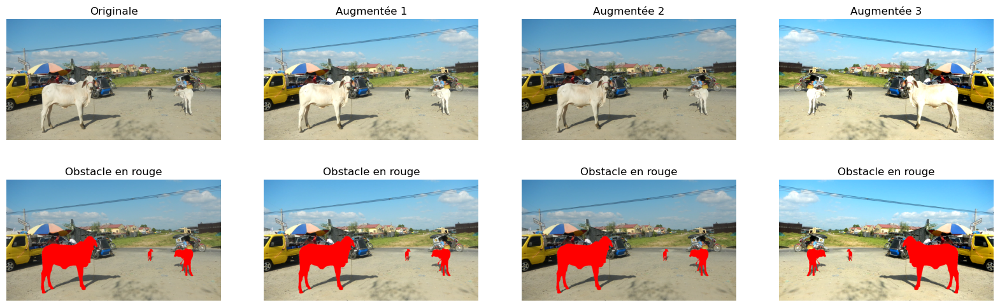

In [36]:
np.random.seed(0)
fig, axes = plt.subplots(2, 4, figsize=(20, 6))

for j in range(4):
    if j == 0:
        p, m = X_train[0], Y_train[0]
        titre = 'Originale'
    else:
        p, m = augmenter(X_train[0], Y_train[0])
        titre = f'Augmentée {j}'

    superposition = p.copy()
    superposition[m == 1] = [1, 0, 0]

    axes[0, j].imshow(p)
    axes[0, j].set_title(titre)
    axes[1, j].imshow(superposition)
    axes[1, j].set_title('Obstacle en rouge')
    for a in axes[:, j]:
        a.axis('off')

plt.show()

# 4. Modeling

**Objectif :** construire et entraîner des modèles qui prédisent, pour chaque pixel, s'il appartient à un obstacle (1) ou au fond (0).

**Pourquoi :** c'est le cœur du projet ; les objectifs DSO1 (precision, recall, F1, IoU, Dice) et DSO2 (recall par taille d'obstacle) seront mesurés sur les prédictions de ces modèles, à la phase 5.

**Méthode :** 5 modèles entraînés dans les mêmes conditions (même découpage, même perte, même optimiseur, même early stopping), pour comparer leurs loss.

| N° | Modèle | Entraînement | Augmentation | Comparaison |
| --- | --- | --- | --- | --- |
| 1 | U-Net simplifié | From scratch | Oui | Référence |
| 2 | U-Net simplifié | From scratch | Non | Effet de l'augmentation (1 vs 2) |
| 3 | Encodeur-décodeur sans raccourcis (type FCN) | From scratch | Oui | Effet des raccourcis (1 vs 3) |
| 4 | U-Net + encodeur ResNet50 | Transfer learning | Oui | Effet du transfer learning (1 vs 4) |
| 5 | DeepLabV3+ + encodeur ResNet50 | Transfer learning | Oui | Effet de l'architecture (4 vs 5) |

- Étapes 19 et 20 : générateur de batchs et construction du modèle 1.
- Étape 21 : entraînement du modèle 1 et courbes de loss.
- Étape 22 : petite grid search sur le modèle 1.
- Étapes 23 à 26 : modèles 2 à 5.
- Étape 27 : comparaison des loss.



**Outil :** Keras (TensorFlow), la bibliothèque du cours, installée par défaut dans Colab.

### Étape 19 : envoyer les images au modèle par batchs

**Objectif :** fournir les images au modèle par petits paquets (batchs), avec la data augmentation et la standardisation.

**Pourquoi :**
- Le GPU ne peut pas traiter les 40 images d'entraînement d'un coup en pleine résolution : on les envoie par batchs de quelques images.
- La data augmentation (étape 18) doit être appliquée pendant l'entraînement, pour que chaque epoch voie des variantes différentes.
- La standardisation doit être appliquée à toutes les images, avec les statistiques de l'entraînement (étape 17b).

**Méthode :**
- 19a : charger TensorFlow et vérifier que le GPU est activé.
- 19b : écrire le générateur de batchs d'entraînement.
- 19c : préparer la validation (standardisée, jamais augmentée).
- 19d : tester le générateur sur un batch.

**Ce qu'on cherche :** des batchs aux bonnes dimensions, prêts à être envoyés au modèle.

#### Étape 19a : charger TensorFlow et vérifier le GPU
**Objectif :** s'assurer que l'entraînement tournera sur le GPU, beaucoup plus rapide que le processeur.

In [37]:
import tensorflow as tf

print("Version de TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices('GPU'))
tf.random.set_seed(42)

Version de TensorFlow : 2.21.0
GPU disponible : []


**Résultat attendu :** dans Colab, une liste avec un GPU. En local dans VS Code, une liste vide `[]` est normale (TensorFlow n'utilise pas le GPU sous Windows) : le notebook tourne alors sur le processeur. Ce n'est pas gênant, car les modèles ne sont pas réentraînés (`REENTRAINER = False`) : on recharge leurs poids, et les prédictions sur 10 images restent rapides.

#### Étape 19b : le générateur de batchs d'entraînement
**Objectif :** fabriquer, à la demande du modèle, un batch d'images standardisées avec leurs masques, augmentées ou non (`augmentation=False` servira au modèle 2).

In [38]:
def standardiser(photo):
    return (photo - moyenne) / ecart_type

def generateur_entrainement(batch_size, augmentation=True):
    while True:
        indices = np.random.permutation(len(X_train))
        for debut in range(0, len(indices) - batch_size + 1, batch_size):
            lot = indices[debut:debut + batch_size]
            photos, masques = [], []
            for i in lot:
                if augmentation:
                    p, m = augmenter(X_train[i], Y_train[i])
                else:
                    p, m = X_train[i], Y_train[i]
                photos.append(standardiser(p))
                masques.append(m)
            yield np.stack(photos).astype(np.float32), np.stack(masques)[..., None].astype(np.float32)

#### Étape 19c : préparer la validation
**Objectif :** standardiser les images de validation une seule fois, sans augmentation.

In [39]:
X_val_std = standardiser(X_val).astype(np.float32)
Y_val_k = Y_val[..., None].astype(np.float32)

print("Validation :", X_val_std.shape, Y_val_k.shape)

Validation : (10, 720, 1280, 3) (10, 720, 1280, 1)


#### Étape 19d : tester le générateur sur un batch
**Objectif :** vérifier la forme, le type et les valeurs d'un batch avant de l'envoyer au modèle.

In [40]:
gen_test = generateur_entrainement(batch_size=2)
photos_lot, masques_lot = next(gen_test)

print("Photos du batch :", photos_lot.shape, photos_lot.dtype)
print("Masques du batch :", masques_lot.shape, np.unique(masques_lot))
print("Moyenne des photos standardisées :", photos_lot.mean().round(2))

del gen_test, photos_lot, masques_lot

Photos du batch : (2, 720, 1280, 3) float32
Masques du batch : (2, 720, 1280, 1) [0. 1.]
Moyenne des photos standardisées : 0.29


**Résultat attendu :**
- photos `(2, 720, 1280, 3)` en `float32` ;
- masques `(2, 720, 1280, 1)` avec les valeurs `[0. 1.]` ;
- moyenne des photos standardisées proche de 0 sur l'ensemble de l'entraînement (sur un seul batch de 2 images augmentées, elle peut s'en écarter) ;
- validation `(10, 720, 1280, 3)` et `(10, 720, 1280, 1)`.

**Conclusions :**
- Photos `(2, 720, 1280, 3)` en `float32` et masques `(2, 720, 1280, 1)` : le générateur fournit des batchs au format attendu par Keras, en pleine résolution.
- Masques à `[0. 1.]` : l'augmentation (flip) n'a créé aucune valeur intermédiaire, les masques restent binaires.
- Moyenne du batch à 0,29 (et non 0) : normal, la standardisation met la moyenne à 0 sur les 40 images d'entraînement, pas sur chaque batch ; ces 2 images sont plus claires que la moyenne (environ 0,29 écart-type au-dessus), en partie à cause de la luminosité aléatoire (×0,7 à ×1,3). Le batch est tiré au hasard : ce chiffre change à chaque exécution.
- Validation `(10, 720, 1280, 3)` et `(10, 720, 1280, 1)` : 10 images, standardisées avec les statistiques de l'entraînement, prêtes pour l'étape 21.

### Étape 20 : modèle 1, un CNN encodeur-décodeur construit from scratch

**Objectif :** construire un réseau qui reçoit une photo 720 × 1280 et renvoie une carte de même taille, avec pour chaque pixel la probabilité d'être un obstacle.

**Pourquoi :**
- Un CNN de classification réduit l'image jusqu'à une seule réponse ; ici, il faut une réponse **par pixel** (DSO1).
- L'**encodeur** réduit l'image par étapes (convolution + pooling) : il comprend *ce qu'il y a* dans l'image, mais perd la position précise.
- Le **décodeur** agrandit la carte jusqu'à la taille d'origine : il retrouve *où* est l'obstacle.
- Des **connexions de raccourci** recopient les cartes de l'encodeur dans le décodeur, à la même taille : elles rendent les détails fins perdus au pooling, indispensables pour les petits obstacles (DSO2).
- Ce modèle sert de référence « from scratch », à comparer au modèle 2 en transfer learning (étape 23).

**Méthode :**
- 20a : un bloc de base (deux convolutions 3 × 3 + ReLU).
- 20b : le modèle complet, avec 4 réductions de moitié (720 et 1280 sont divisibles par 16) et une sigmoïde en sortie.
- 20c : construire le modèle et afficher son résumé.
- 20d : le tester sur un batch, sans entraînement.

**Ce qu'on cherche :** un modèle qui accepte un batch et sort une carte `(batch, 720, 1280, 1)` avec des valeurs entre 0 et 1.

#### Étape 20a : le bloc de convolution
**Objectif :** écrire une seule fois le motif répété à chaque niveau du réseau.

In [41]:
from tensorflow import keras
from tensorflow.keras import layers

def bloc_conv(x, filtres, dropout=0.0):
    x = layers.Conv2D(filtres, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(filtres, 3, padding='same', activation='relu')(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    return x

#### Étape 20b : le modèle complet
**Objectif :** assembler l'encodeur, le centre et le décodeur, avec les connexions de raccourci.

In [42]:
def construire_modele_1(filtres=16, dropout=0.0):
    entree = keras.Input(shape=(720, 1280, 3))

    # Encodeur : 4 réductions de moitié
    e1 = bloc_conv(entree, filtres)                                     # 720 × 1280
    e2 = bloc_conv(layers.MaxPooling2D()(e1), filtres * 2)              # 360 × 640
    e3 = bloc_conv(layers.MaxPooling2D()(e2), filtres * 4)              # 180 × 320
    e4 = bloc_conv(layers.MaxPooling2D()(e3), filtres * 8)              # 90 × 160
    centre = bloc_conv(layers.MaxPooling2D()(e4), filtres * 16, dropout)  # 45 × 80

    # Décodeur : on agrandit et on recolle la carte de l'encodeur de même taille
    d4 = bloc_conv(layers.Concatenate()([layers.UpSampling2D()(centre), e4]), filtres * 8)
    d3 = bloc_conv(layers.Concatenate()([layers.UpSampling2D()(d4), e3]), filtres * 4)
    d2 = bloc_conv(layers.Concatenate()([layers.UpSampling2D()(d3), e2]), filtres * 2)
    d1 = bloc_conv(layers.Concatenate()([layers.UpSampling2D()(d2), e1]), filtres)

    sortie = layers.Conv2D(1, 1, activation='sigmoid')(d1)
    return keras.Model(entree, sortie, name='modele_1_cnn')

#### Étape 20c : construire le modèle et afficher son résumé
**Objectif :** vérifier la taille des cartes à chaque niveau et le nombre de paramètres à apprendre.

In [43]:
modele_1 = construire_modele_1(filtres=16, dropout=0.0)
modele_1.summary()

Model: "modele_1_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 720, 1280, │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 720, 1280, │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 720, 1280, │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 360, 640,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 360, 640,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 360, 640,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 180, 320,  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 180, 320,  │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 180, 320,  │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 90, 160,   │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 90, 160,   │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 90, 160,   │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 45, 80,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 45, 80,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 45, 80,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 90, 160,   │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 90, 160,   │          0 │ up_sampling2d[0]

 Total params: 1,962,625 (7.49 MB)

 Trainable params: 1,962,625 (7.49 MB)

 Non-trainable params: 0 (0.00 B)

**Ce qu'on cherche :** des cartes de 720 × 1280 au début et à la fin, 45 × 80 au centre, et le nombre total de paramètres (*Total params*), à noter pour la comparaison avec le modèle 2.

**Conclusions :**
- La carte de sortie fait 720 × 1280 avec 1 canal : une probabilité par pixel, à la taille exacte des masques.
- Les 4 poolings et les 4 agrandissements retombent juste (720 et 1280 divisibles par 16) : aucun redimensionnement n'est nécessaire.
- 1 962 625 paramètres, tous entraînables : un modèle léger (7,49 Mo), adapté à 40 images d'entraînement ; ce chiffre servira de comparaison avec le modèle 2.

#### Étape 20d : tester le modèle sur un batch
**Objectif :** vérifier que le modèle accepte un batch du générateur et renvoie une carte de la bonne taille, avant de lancer un long entraînement.

In [44]:
gen_test = generateur_entrainement(batch_size=2)
photos_lot, masques_lot = next(gen_test)
sortie_lot = modele_1.predict(photos_lot, verbose=0)

print("Entrée :", photos_lot.shape)
print("Sortie du modèle :", sortie_lot.shape)
print("Masques attendus :", masques_lot.shape)
print("Valeurs de sortie : min", sortie_lot.min().round(3), "| max", sortie_lot.max().round(3))

del gen_test, photos_lot, masques_lot, sortie_lot

Entrée : (2, 720, 1280, 3)
Sortie du modèle : (2, 720, 1280, 1)
Masques attendus : (2, 720, 1280, 1)
Valeurs de sortie : min 0.46 | max 0.601




**Conclusions :**
- Sortie `(2, 720, 1280, 1)` identique aux masques `(2, 720, 1280, 1)` : la perte pourra comparer la prédiction et le masque pixel par pixel.
- Valeurs entre 0,46 et 0,601 : la sigmoïde renvoie bien des probabilités, proches de 0,5 car les poids sont encore aléatoires.


### Étape 21 : entraîner le modèle 1

**Objectif :** apprendre au U-Net simplifié à reconnaître les pixels d'obstacle, sur les 40 images d'entraînement, en surveillant la validation.

**Pourquoi :**
- Pour l'instant, le modèle répond environ 0,5 partout (étape 20d) : ses poids sont aléatoires.
- L'entraînement ajuste les poids pour que la sortie se rapproche des masques ; la **loss** mesure l'écart.
- Ce modèle est la référence : les modèles 2 à 5 seront comparés à lui.

**Méthode :**
- 21a : la fonction de perte BCE + Dice.
- 21b : connecter Google Drive pour sauvegarder les poids.
- 21c : une fonction d'entraînement commune aux 5 modèles (Adam, early stopping, sauvegarde).
- 21d : entraîner le modèle 1.
- 21e : tracer les courbes de loss.

**Ce qu'on cherche :** une loss de validation qui baisse puis se stabilise, et des courbes d'entraînement et de validation proches (pas de surapprentissage fort).

#### Étape 21a : la fonction de perte BCE + Dice
**Objectif :** définir l'erreur que le modèle doit réduire, adaptée à des obstacles qui n'occupent qu'une petite partie de l'image (médiane 6,62 %, étape 9).

In [45]:
def coef_dice(y_vrai, y_pred, lisse=1.0):
    intersection = tf.reduce_sum(y_vrai * y_pred, axis=[1, 2, 3])
    somme = tf.reduce_sum(y_vrai, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return tf.reduce_mean((2 * intersection + lisse) / (somme + lisse))

def perte_bce_dice(y_vrai, y_pred):
    bce = tf.reduce_mean(keras.losses.binary_crossentropy(y_vrai, y_pred))
    return bce + (1 - coef_dice(y_vrai, y_pred))

#### Étape 21b : le dossier de sauvegarde des modèles
**Objectif :** indiquer où se trouvent (et où seraient sauvegardés) les poids et l'historique de chaque modèle. Dans Colab, c'était Google Drive ; en local, c'est le dossier `RoadAnomaly_modeles` téléchargé depuis Drive.

In [46]:
os.makedirs(DOSSIER_MODELES, exist_ok=True)
print("Dossier de sauvegarde :", DOSSIER_MODELES)
print("Fichiers présents :", len(os.listdir(DOSSIER_MODELES)))

Dossier de sauvegarde : c:\Projet DeepLearning\RoadAnomaly_modeles
Fichiers présents : 25


#### Étape 21c : la fonction d'entraînement commune
**Objectif :** entraîner n'importe quel modèle dans exactement les mêmes conditions, pour que la comparaison des loss soit juste.

In [ ]:
import time

def entrainer(modele, nom, batch_size=2, learning_rate=1e-3, epochs=50, patience=10, augmentation=True):
    # Déjà entraîné (dans Colab) : on recharge les poids et l'historique au lieu de réentraîner
    chemin_poids = os.path.join(DOSSIER_MODELES, nom + '.weights.h5')
    chemin_histo = os.path.join(DOSSIER_MODELES, nom + '_historique.json')
    if not REENTRAINER and os.path.exists(chemin_poids) and os.path.exists(chemin_histo):
        modele.load_weights(chemin_poids)
        with open(chemin_histo) as f:
            histo = json.load(f)
        meilleure = int(np.argmin(histo['val_loss']))
        print(f"{nom} : déjà entraîné, poids et historique rechargés ({len(histo['loss'])} epochs)")
        print(f"Meilleure epoch : {meilleure + 1} | loss validation {histo['val_loss'][meilleure]:.4f} | Dice validation {histo['val_coef_dice'][meilleure]:.4f}")
        return histo, None

    modele.compile(optimizer=keras.optimizers.Adam(learning_rate),
                   loss=perte_bce_dice, metrics=[coef_dice])

    rappels = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(os.path.join(DOSSIER_MODELES, nom + '.weights.h5'),
                                        monitor='val_loss', save_best_only=True, save_weights_only=True),
    ]

    debut = time.time()
    historique = modele.fit(generateur_entrainement(batch_size, augmentation),
                            steps_per_epoch=len(X_train) // batch_size,
                            validation_data=(X_val_std, Y_val_k),
                            validation_batch_size=batch_size,
                            epochs=epochs, callbacks=rappels, verbose=2)
    duree = (time.time() - debut) / 60

    histo = {cle: [float(v) for v in valeurs] for cle, valeurs in historique.history.items()}
    with open(os.path.join(DOSSIER_MODELES, nom + '_historique.json'), 'w') as f:
        json.dump(histo, f)

    meilleure = int(np.argmin(histo['val_loss']))
    print(f"{nom} : {len(histo['loss'])} epochs en {duree:.1f} min")
    print(f"Meilleure epoch : {meilleure + 1} | loss validation {histo['val_loss'][meilleure]:.4f} | Dice validation {histo['val_coef_dice'][meilleure]:.4f}")
    return histo, duree

#### Étape 21d : entraîner le modèle 1
**Objectif :** lancer l'entraînement du U-Net simplifié avec augmentation (batch size 2, learning rate 0,001, 50 epochs maximum, arrêt après 10 epochs sans amélioration).

*Cette cellule peut prendre plusieurs minutes. Si elle affiche « out of memory » : réduire `batch_size` à 1.*

In [48]:
keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

modele_1 = construire_modele_1(filtres=16, dropout=0.0)
historique_1, duree_1 = entrainer(modele_1, 'modele_1_unet')


modele_1_unet : déjà entraîné, poids et historique rechargés (22 epochs)
Meilleure epoch : 12 | loss validation 1.0568 | Dice validation 0.2886


**Ce qu'on cherche :** le numéro de la meilleure epoch, la loss et le Dice de validation à cette epoch.

**Conclusions :**
- Meilleure epoch : 12, avec une loss de validation de 1,0568 et un Dice de validation de 0,2886 : ce sont ces poids que l'early stopping a gardés.
- L'entraînement s'est arrêté après 22 epochs, car la loss de validation n'a plus battu celle de l'epoch 12 pendant 10 epochs.
- Sur le GPU de Colab, une epoch prenait environ 6 s : le batch size 2 tient en mémoire en pleine résolution.

#### Étape 21e : tracer les courbes de loss
**Objectif :** voir comment la loss d'entraînement et la loss de validation évoluent à chaque epoch, pour repérer un éventuel surapprentissage.

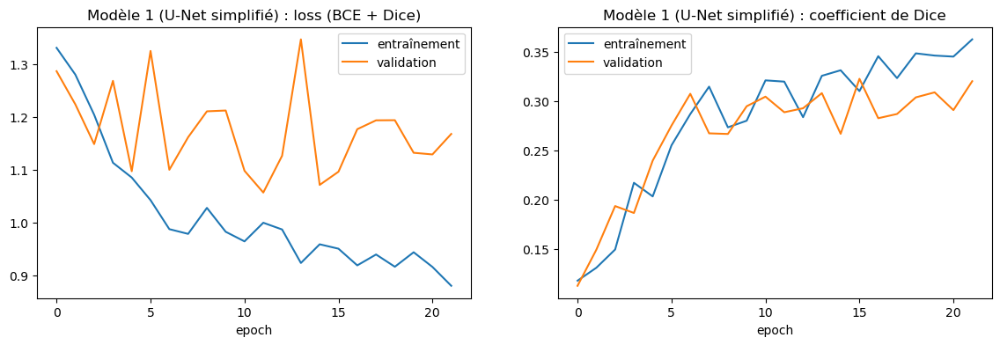

In [49]:
def tracer_courbes(histo, titre):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(histo['loss'], label='entraînement')
    axes[0].plot(histo['val_loss'], label='validation')
    axes[0].set_title(titre + ' : loss (BCE + Dice)')
    axes[1].plot(histo['coef_dice'], label='entraînement')
    axes[1].plot(histo['val_coef_dice'], label='validation')
    axes[1].set_title(titre + ' : coefficient de Dice')
    for a in axes:
        a.set_xlabel('epoch')
        a.legend()
    plt.show()

tracer_courbes(historique_1, 'Modèle 1 (U-Net simplifié)')

**Ce qu'on cherche :**
- les deux loss baissent : le modèle apprend ;
- la loss de validation se stabilise : l'early stopping a gardé les meilleurs poids ;
- un grand écart (entraînement très bas, validation qui remonte) serait le signe d'un surapprentissage.

**Conclusions :**
- La loss d'entraînement baisse régulièrement (1,33 → 0,88) : le modèle apprend.
- La loss de validation oscille fortement (entre 1,06 et 1,35) : avec seulement 10 images de validation, chaque image pèse beaucoup sur le score.
- Pas de surapprentissage : le Dice d'entraînement et le Dice de validation montent ensemble et restent proches (≈ 0,36 et ≈ 0,32 à la fin).
- Le modèle n'a pas fini d'apprendre : le Dice monte encore à la dernière epoch et reste faible (≈ 0,3). L'early stopping, avec une patience de 10, s'est arrêté trop tôt à cause des oscillations de la validation.
- Pour la suite : plus d'epochs (100) et une patience plus grande (20), et une grid search sur le learning rate et le batch size (étape 22).
- Le dropout n'est pas utile pour l'instant, puisqu'il n'y a pas de surapprentissage.

### Étape 22 : petite grid search sur le modèle 1

**Objectif :** trouver la meilleure combinaison de learning rate et de batch size pour le U-Net simplifié, en la jugeant sur la validation.

**Pourquoi :**
- À l'étape 21, le modèle apprend sans surapprentissage, mais s'arrête trop tôt (Dice ≈ 0,3, encore en hausse) et la loss de validation oscille.
- Un learning rate plus petit rend l'apprentissage plus régulier ; un batch size plus grand rend chaque correction moins bruitée.
- Les réglages retenus serviront ensuite aux modèles 2 à 5, pour que la comparaison des loss reste juste.

**Méthode :**
- 22a : entraîner 4 combinaisons (learning rate 0,001 ou 0,0001 × batch size 2 ou 4), avec 100 epochs maximum et une patience de 20.
- 22b : comparer les combinaisons dans un tableau, trié par loss de validation.
- 22c : retenir la meilleure, recharger ses poids comme modèle 1 final et tracer ses courbes.

**Ce qu'on cherche :** la combinaison avec la plus petite loss de validation, et un Dice de validation supérieur à celui de l'étape 21 (0,2886).

*Le dropout n'est pas testé : il sert contre le surapprentissage, qui n'apparaît pas à l'étape 21.*

#### Étape 22a : entraîner les 4 combinaisons
Learning rate : 0.001 ou 0.0001
ce sont deux valeurs classiques pour l'optimiseur Adam.
- 0.001 (10⁻³) : taux d'apprentissage relativement élevé → les poids sont ajustés avec des pas plus grands.
- 0.0001 (10⁻⁴) : taux d'apprentissage plus faible → les poids sont ajustés avec des pas plus petits.
Batch size : 2 ou 4

In [50]:
combinaisons = [(1e-3, 2), (1e-4, 2), (1e-3, 4), (1e-4, 4)]
resultats_grid = []

for lr, bs in combinaisons:
    keras.backend.clear_session()
    tf.random.set_seed(42)
    np.random.seed(42)
    nom = f'grid_lr{lr}_bs{bs}'
    print(f"\n===== learning rate {lr} | batch size {bs} =====")
    try:
        modele = construire_modele_1(filtres=16, dropout=0.0)
        histo, duree = entrainer(modele, nom, batch_size=bs, learning_rate=lr, epochs=100, patience=20)
    except tf.errors.ResourceExhaustedError:
        print("Mémoire insuffisante : combinaison ignorée")
        continue
    m = int(np.argmin(histo['val_loss']))
    resultats_grid.append({'learning_rate': lr, 'batch_size': bs, 'epochs': len(histo['loss']),
                           'meilleure_epoch': m + 1, 'val_loss': round(histo['val_loss'][m], 4),
                           'val_dice': round(histo['val_coef_dice'][m], 4), 'duree_min': round(duree, 1) if duree is not None else None})
    del modele


===== learning rate 0.001 | batch size 2 =====
grid_lr0.001_bs2 : déjà entraîné, poids et historique rechargés (35 epochs)
Meilleure epoch : 15 | loss validation 1.0867 | Dice validation 0.2607

===== learning rate 0.0001 | batch size 2 =====
grid_lr0.0001_bs2 : déjà entraîné, poids et historique rechargés (99 epochs)
Meilleure epoch : 79 | loss validation 0.9231 | Dice validation 0.4053

===== learning rate 0.001 | batch size 4 =====
grid_lr0.001_bs4 : déjà entraîné, poids et historique rechargés (100 epochs)
Meilleure epoch : 87 | loss validation 0.9797 | Dice validation 0.4258

===== learning rate 0.0001 | batch size 4 =====
grid_lr0.0001_bs4 : déjà entraîné, poids et historique rechargés (80 epochs)
Meilleure epoch : 60 | loss validation 1.0390 | Dice validation 0.3131


#### Étape 22b : comparer les combinaisons
**Objectif :** classer les combinaisons de la meilleure à la moins bonne loss de validation, et garder le tableau sur Google Drive.

In [51]:
chemin_grid = os.path.join(DOSSIER_MODELES, 'grid_search_modele_1.csv')
if not REENTRAINER and os.path.exists(chemin_grid):
    df_grid = pd.read_csv(chemin_grid)
else:
    df_grid = pd.DataFrame(resultats_grid).sort_values('val_loss').reset_index(drop=True)
    df_grid.to_csv(chemin_grid, index=False)
df_grid

,learning_rate,batch_size,epochs,meilleure_epoch,val_loss,val_dice,duree_min
0,0.0001,2,99,79,0.9231,0.4053,9.5
1,0.0010,4,100,87,0.9797,0.4258,10.9
2,0.0001,4,80,60,1.0390,0.3131,7.7
3,0.0010,2,35,15,1.0867,0.2607,3.4


**Conclusions :**
- Meilleure combinaison : learning rate 0,0001 et batch size 2, avec une loss de validation de 0,9231 (epoch 79).
- Nette amélioration par rapport à l'étape 21 : Dice de validation 0,4053 au lieu de 0,2886.
- Le réglage de l'étape 21 (0,001 et 2) est le moins bon (loss 1,0867) : un grand learning rate avec des batchs de 2 images rend l'apprentissage instable, et l'early stopping s'arrête tôt (35 epochs).
- Le batch size 4 tient en mémoire en pleine résolution.
- La combinaison 0,001 / 4 a un Dice un peu meilleur (0,4258) mais une loss moins bonne (0,9797) : on garde le critère fixé à l'avance, la loss de validation. Avec 10 images de validation, un écart de 0,02 de Dice n'est pas significatif.
- Chaque combinaison prend au plus 11 min : les 4 autres modèles sont faisables dans le temps restant.

On conserve les hyperparamètres sélectionnés :  ( ligne1) 
- Learning rate = 0.0001
- Batch size = 2

#### Étape 22c : retenir la meilleure combinaison
**Objectif :** fixer les réglages communs aux 5 modèles, recharger les meilleurs poids comme modèle 1 final et tracer ses courbes.

Réglages retenus pour les 5 modèles : {'learning_rate': 0.0001, 'batch_size': 2, 'epochs': 100, 'patience': 20}


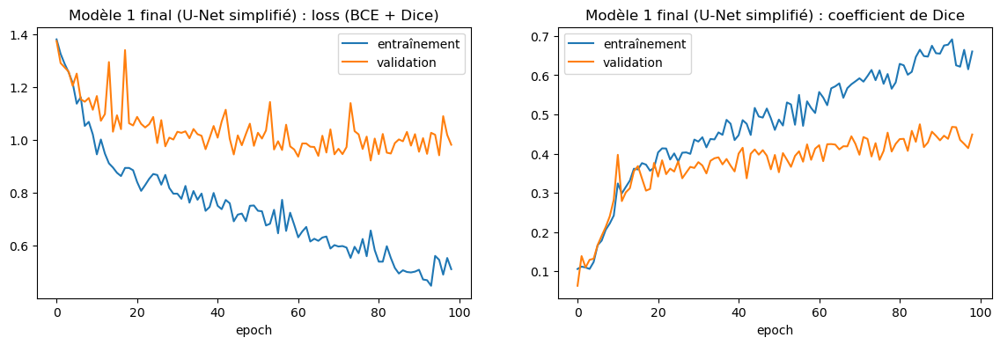

In [52]:
meilleur = df_grid.iloc[0]
REGLAGES = {'learning_rate': float(meilleur['learning_rate']), 'batch_size': int(meilleur['batch_size']),
            'epochs': 100, 'patience': 20}
nom_meilleur = f"grid_lr{REGLAGES['learning_rate']}_bs{REGLAGES['batch_size']}"
print("Réglages retenus pour les 5 modèles :", REGLAGES)

keras.backend.clear_session()
modele_1 = construire_modele_1(filtres=16, dropout=0.0)
modele_1.load_weights(os.path.join(DOSSIER_MODELES, nom_meilleur + '.weights.h5'))
with open(os.path.join(DOSSIER_MODELES, nom_meilleur + '_historique.json')) as f:
    historique_1 = json.load(f)

tracer_courbes(historique_1, 'Modèle 1 final (U-Net simplifié)')

Le modèle apprend sur les images d'entraînement, mais il a encore du mal à bien reconnaître les obstacles dans les images de validation.

**Conclusions :**
- Réglages retenus pour les 5 modèles : learning rate 0,0001, batch size 2, 100 epochs maximum, patience 20.
- Les deux loss baissent ensemble pendant environ 20 epochs ; ensuite, la loss de validation se stabilise vers 1,0 alors que celle d'entraînement continue de baisser (jusqu'à ≈ 0,5).
- Même écart sur le Dice : environ 0,67 en entraînement contre 0,45 en validation à la fin.
- Cet écart croissant est un début de surapprentissage, modéré : la loss de validation ne remonte pas, et le Dice de validation progresse encore lentement.
- L'early stopping a gardé les poids de l'epoch 79 et arrêté l'entraînement à l'epoch 99 : la limite de 100 epochs n'a pas bridé le modèle.
- Le modèle 2 (sans augmentation) montrera si ce surapprentissage serait plus fort sans augmentation.

### Étape 23 : modèle 2, U-Net simplifié sans data augmentation

**Objectif :** entraîner exactement le même modèle que le modèle 1, avec les mêmes réglages, mais sans data augmentation.

**Pourquoi :**
- À l'étape 22c, le modèle 1 montre un début de surapprentissage (Dice 0,67 en entraînement contre 0,45 en validation).
- La data augmentation (étape 18) est censée limiter ce surapprentissage : en la retirant, on mesure ce qu'elle apporte réellement.
- Une seule chose change entre les modèles 1 et 2 : la comparaison est donc juste (étude d'ablation).

**Méthode :**
- 23a : entraîner le modèle 2 avec les réglages retenus (`REGLAGES`) et `augmentation=False`.
- 23b : tracer ses courbes de loss et de Dice.

**Ce qu'on cherche :** un écart entre entraînement et validation plus grand que pour le modèle 1, et une loss de validation moins bonne que 0,9231, si l'augmentation est utile.

#### Étape 23a : entraîner le modèle 2
**Objectif :** entraîner le U-Net simplifié sans augmentation, dans les mêmes conditions que le modèle 1 (même graine aléatoire, mêmes réglages).

In [53]:
keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

modele_2 = construire_modele_1(filtres=16, dropout=0.0)
historique_2, duree_2 = entrainer(modele_2, 'modele_2_unet_sans_aug', augmentation=False, **REGLAGES)

modele_2_unet_sans_aug : déjà entraîné, poids et historique rechargés (57 epochs)
Meilleure epoch : 37 | loss validation 0.9898 | Dice validation 0.3802


**Conclusions :**
- Sans augmentation, le modèle est moins bon sur la validation : loss 0,9898 au lieu de 0,9231 pour le modèle 1, Dice 0,3802 au lieu de 0,4053.
- Il cesse de progresser beaucoup plus tôt : meilleure epoch 37 au lieu de 79, arrêt à l'epoch 57 au lieu de 99.
- Explication : il voit toujours exactement les mêmes 40 images, les apprend plus vite par cœur, et n'apprend plus rien d'utile pour les nouvelles images.
- La data augmentation est donc utile ici : elle prolonge l'apprentissage utile et améliore les résultats sur la validation.
- Limite : un seul entraînement par modèle et 10 images de validation ; l'écart va dans le sens attendu mais sera à confirmer sur le test (phase 5).

#### Étape 23b : tracer les courbes du modèle 2


**Objectif :** comparer l'écart entre entraînement et validation avec celui du modèle 1 (étape 22c), pour voir si le surapprentissage est plus fort sans augmentation.

**Ce qu'on cherche :** un écart entre les courbes d'entraînement et de validation qui se creuse plus vite et plus fort que pour le modèle 1 (étape 22c : Dice 0,67 contre 0,45 à la fin).

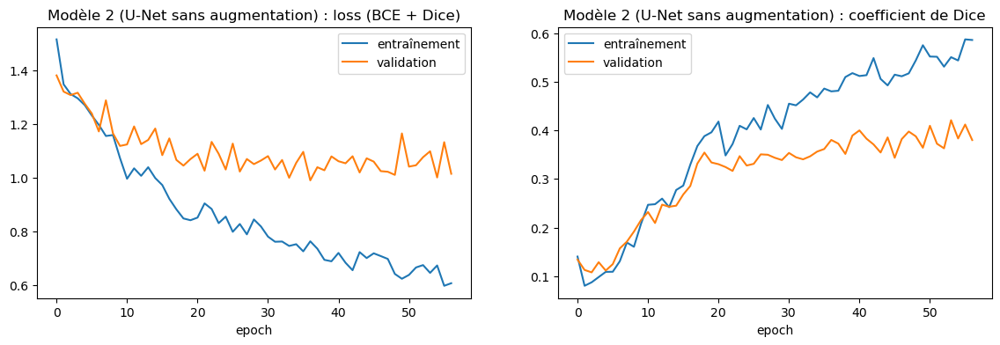

In [54]:
tracer_courbes(historique_2, 'Modèle 2 (U-Net sans augmentation)')

**Conclusions :**
- L'écart entre entraînement et validation apparaît dès l'epoch 10 environ, contre environ 20 pour le modèle 1 : le surapprentissage arrive plus tôt.
- À la fin (epoch 57), le Dice vaut environ 0,59 en entraînement contre 0,38 en validation, et la loss environ 0,6 contre 1,05.
- La loss de validation plafonne vers 1,05, plus haut que celle du modèle 1 (vers 1,0).
- Sans augmentation, le modèle apprend les 40 images d'entraînement plus vite par cœur et généralise moins bien : la data augmentation protège bien contre le surapprentissage.

### Étape 24 : modèle 3, encodeur-décodeur sans raccourcis (type FCN)

**Objectif :** entraîner le même réseau que le modèle 1, mais sans les connexions de raccourci.

**Pourquoi :**
- Les connexions de raccourci recopient les détails fins de l'encodeur dans le décodeur ; elles devraient aider à retrouver les petits obstacles (DSO2).
- En les retirant, et en gardant tout le reste identique (mêmes couches, mêmes réglages, même augmentation), on mesure ce qu'elles apportent réellement (étude d'ablation).
- C'est l'idée du FCN, le premier réseau de segmentation sémantique : l'image est réduite puis agrandie, sans réinjecter les détails.

**Méthode :**
- 24a : construire le modèle 3 et compter ses paramètres.
- 24b : l'entraîner avec les réglages retenus (`REGLAGES`).
- 24c : tracer ses courbes.

**Ce qu'on cherche :** une loss de validation moins bonne que celle du modèle 1 (0,9231), si les raccourcis sont utiles.

#### Étape 24a : construire le modèle 3
**Objectif :** écrire le modèle type FCN (le décodeur agrandit la carte sans recoller les cartes de l'encodeur) et vérifier sa taille de sortie.

In [55]:
def construire_modele_3(filtres=16, dropout=0.0):
    entree = keras.Input(shape=(720, 1280, 3))

    # Encodeur : identique au modèle 1
    e1 = bloc_conv(entree, filtres)                                     # 720 × 1280
    e2 = bloc_conv(layers.MaxPooling2D()(e1), filtres * 2)              # 360 × 640
    e3 = bloc_conv(layers.MaxPooling2D()(e2), filtres * 4)              # 180 × 320
    e4 = bloc_conv(layers.MaxPooling2D()(e3), filtres * 8)              # 90 × 160
    centre = bloc_conv(layers.MaxPooling2D()(e4), filtres * 16, dropout)  # 45 × 80

    # Décodeur : on agrandit sans recoller les cartes de l'encodeur
    d4 = bloc_conv(layers.UpSampling2D()(centre), filtres * 8)
    d3 = bloc_conv(layers.UpSampling2D()(d4), filtres * 4)
    d2 = bloc_conv(layers.UpSampling2D()(d3), filtres * 2)
    d1 = bloc_conv(layers.UpSampling2D()(d2), filtres)

    sortie = layers.Conv2D(1, 1, activation='sigmoid')(d1)
    return keras.Model(entree, sortie, name='modele_3_fcn')

keras.backend.clear_session()
modele_3 = construire_modele_3(filtres=16, dropout=0.0)
print("Sortie :", modele_3.output_shape)
print("Nombre de paramètres :", modele_3.count_params())

Sortie : (None, 720, 1280, 1)
Nombre de paramètres : 1766785


**Conclusions :**
- Sortie `(None, 720, 1280, 1)` : même taille que les masques, comme le modèle 1.
- 1 766 785 paramètres contre 1 962 625 pour le modèle 1 : sans les cartes recollées, le décodeur reçoit moins de canaux, donc ses convolutions ont moins de poids (environ 10 % de moins).
- Seule différence avec le modèle 1 : l'absence de connexions de raccourci. La comparaison des deux mesurera donc leur apport.

#### Étape 24b : entraîner le modèle 3
**Objectif :** entraîner le modèle type FCN dans exactement les mêmes conditions que le modèle 1 (même graine aléatoire, mêmes réglages, avec augmentation).

In [56]:
keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

modele_3 = construire_modele_3(filtres=16, dropout=0.0)
historique_3, duree_3 = entrainer(modele_3, 'modele_3_fcn', augmentation=True, **REGLAGES)

modele_3_fcn : déjà entraîné, poids et historique rechargés (82 epochs)
Meilleure epoch : 62 | loss validation 0.9906 | Dice validation 0.3567


**Conclusions :**
- Le modèle 3 est nettement moins bon que le modèle 1 sur la validation : Dice 0,3567 au lieu de 0,4053, loss 0,9906 au lieu de 0,9231.
- Les connexions de raccourci sont donc utiles : en réinjectant les détails fins de l'encodeur, elles aident le décodeur à dessiner les obstacles au bon endroit.
- L'écart de Dice avec le modèle 1 (−0,05) est deux fois plus grand que celui du modèle 2 sans augmentation (−0,025) : sur ce dataset, les raccourcis comptent plus que l'augmentation.
- Meilleure epoch 62, arrêt à l'epoch 82, en 7,1 min : un peu plus rapide par epoch que le modèle 1, car il a moins de calculs.
- L'effet sur les petits obstacles sera mesuré en phase 5 (recall par taille, DSO2).

#### Étape 24c : tracer les courbes du modèle 3
**Objectif :** vérifier comment le modèle type FCN apprend, et comparer l'écart entre entraînement et validation avec le modèle 1.

**Ce qu'on cherche :** des courbes qui plafonnent plus bas que celles du modèle 1 (Dice de validation sous 0,40), signe que le réseau manque des détails fins.

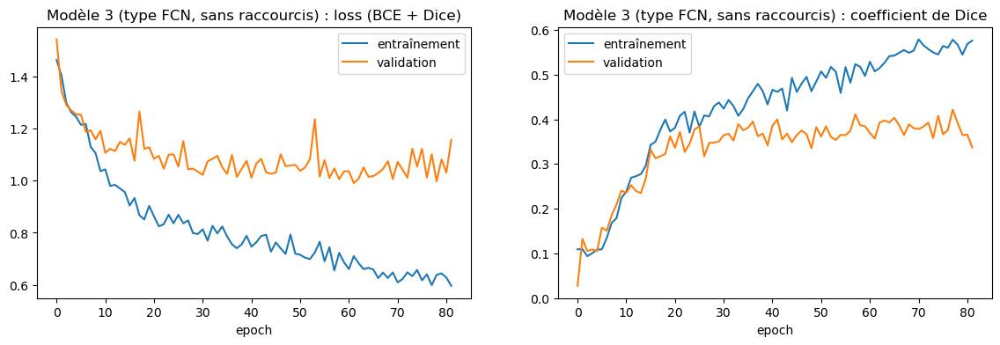

In [57]:
tracer_courbes(historique_3, 'Modèle 3 (type FCN, sans raccourcis)')

**Conclusions :**
- Le Dice de validation plafonne entre 0,35 et 0,40 dès l'epoch 20 environ ; la loss de validation reste vers 1,05.
- Même en entraînement, le Dice n'atteint que ≈ 0,58 (contre ≈ 0,67 pour le modèle 1) : sans raccourcis, le réseau a du mal à dessiner des contours précis, même sur les images qu'il connaît.
- L'écart entre entraînement et validation se creuse à partir de l'epoch 20 environ, comme pour le modèle 1, mais toutes les courbes plafonnent plus bas.

### Étape 25 : modèle 4, U-Net avec encodeur ResNet50 pré-entraîné (transfer learning)

**Objectif :** remplacer l'encodeur du U-Net par ResNet50, un réseau déjà entraîné sur ImageNet (1,2 million d'images), et garder le même décodeur en U.

**Pourquoi :**
- Avec 40 images d'entraînement, un encodeur construit de zéro apprend peu de choses générales (formes, textures, objets).
- ResNet50 sait déjà reconnaître ces éléments : on réutilise ce savoir (transfer learning, demandé par le sujet).
- La forme en U est la même que celle du modèle 1 : la comparaison 1 vs 4 mesure l'apport du pré-entraînement.

**Méthode :**
- 25a : construire le modèle (ResNet50 coupé après 4 réductions, décodeur en U, conversion des images au format ImageNet).
- 25b : 1er temps, encodeur gelé : seul le décodeur apprend.
- 25c : 2e temps, fine-tuning : on dégèle l'encodeur avec un learning rate 10 fois plus petit.
- 25d : tracer les courbes des deux temps.

**Ce qu'on cherche :** une loss de validation meilleure que celle du modèle 1 (0,9231), si le pré-entraînement aide.

#### Étape 25a : construire le modèle 4
**Objectif :** assembler l'encodeur ResNet50 (poids ImageNet, gelé au départ) et le décodeur en U, puis vérifier la taille de sortie et le nombre de paramètres.

In [58]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

def construire_modele_4():
    entree = keras.Input(shape=(720, 1280, 3))

    # Retour aux pixels 0-255, puis format ImageNet attendu par ResNet50
    x = layers.Lambda(lambda t: preprocess_input((t * ecart_type + moyenne) * 255.0))(entree)

    # Encodeur : ResNet50 pré-entraîné, coupé après 4 réductions (45 × 80)
    resnet = ResNet50(include_top=False, weights='imagenet', input_shape=(720, 1280, 3))
    noms = ['conv1_relu', 'conv2_block3_out', 'conv3_block4_out', 'conv4_block6_out']
    encodeur = keras.Model(resnet.input, [resnet.get_layer(n).output for n in noms], name='encodeur_resnet50')
    encodeur.trainable = False
    e1, e2, e3, centre = encodeur(x, training=False)   # 360×640, 180×320, 90×160, 45×80

    # Décodeur en U : on agrandit et on recolle les cartes de l'encodeur de même taille
    d3 = bloc_conv(layers.Concatenate()([layers.UpSampling2D()(centre), e3]), 128)  # 90 × 160
    d2 = bloc_conv(layers.Concatenate()([layers.UpSampling2D()(d3), e2]), 64)       # 180 × 320
    d1 = bloc_conv(layers.Concatenate()([layers.UpSampling2D()(d2), e1]), 32)       # 360 × 640
    d0 = bloc_conv(layers.UpSampling2D()(d1), 16)                                    # 720 × 1280

    sortie = layers.Conv2D(1, 1, activation='sigmoid')(d0)
    return keras.Model(entree, sortie, name='modele_4_unet_resnet50'), encodeur

keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

modele_4, encodeur_4 = construire_modele_4()
print("Sortie :", modele_4.output_shape)
print("Paramètres au total :", modele_4.count_params())
print("Paramètres entraînables (encodeur gelé) :", sum(int(np.prod(w.shape)) for w in modele_4.trainable_weights))

Sortie : (None, 720, 1280, 1)
Paramètres au total : 10817649
Paramètres entraînables (encodeur gelé) : 2228465


**Conclusions :**
- Sortie `(None, 720, 1280, 1)` : même taille que les masques, comme les modèles 1 à 3.
- 10 817 649 paramètres au total, environ 5,5 fois plus que le modèle 1 (1 962 625) : l'essentiel vient de l'encodeur ResNet50.
- Seulement 2 228 465 paramètres entraînables (≈ 21 %) : l'encodeur est gelé, seuls le décodeur et la sortie vont apprendre dans le premier temps.
- Les poids ImageNet de ResNet50 ont été téléchargés : l'encodeur part donc d'un savoir déjà acquis sur 1,2 million d'images.

#### Étape 25b : 1er temps, entraîner le décodeur (encodeur gelé)
**Objectif :** apprendre au décodeur à transformer les caractéristiques de ResNet50 en carte d'obstacles, sans modifier les poids ImageNet.

**Pourquoi :** au départ, le décodeur est aléatoire ; si l'encodeur était dégelé tout de suite, les grosses erreurs du décodeur abîmeraient les poids ImageNet.

**Ce qu'on cherche :** une loss de validation qui baisse plus vite et plus bas que celle du modèle 1, grâce aux caractéristiques déjà apprises par ResNet50.

In [59]:
historique_4a, duree_4a = entrainer(modele_4, 'modele_4_unet_resnet50_gele', augmentation=True, **REGLAGES)

modele_4_unet_resnet50_gele : déjà entraîné, poids et historique rechargés (72 epochs)
Meilleure epoch : 52 | loss validation 0.5252 | Dice validation 0.7110


**Conclusions :**
- Le transfer learning change complètement le niveau : Dice de validation 0,7110 contre 0,4053 pour le modèle 1 (+ 0,31), loss presque divisée par deux (0,5252 contre 0,9231).
- Pourtant, le modèle 4 entraîne à peine plus de paramètres que le modèle 1 (2,2 millions contre 2,0) : le gain vient des caractéristiques déjà apprises par ResNet50 sur 1,2 million d'images, pas de la taille du modèle.
- C'est l'écart le plus grand de toutes les comparaisons (sans raccourcis : − 0,05 de Dice ; sans augmentation : − 0,025) : avec seulement 40 images, le savoir préalable compte bien plus que les détails de l'architecture.
- Meilleure epoch 52, arrêt à l'epoch 72, en 8,6 min.

#### Étape 25c : 2e temps, fine-tuning (encodeur dégelé)
**Objectif :** dégeler ResNet50 et ajuster tout le réseau avec un learning rate 10 fois plus petit (0,00001), pour adapter l'encodeur aux images de route.

**Pourquoi :** les poids ImageNet sont généraux (animaux, objets du quotidien) ; un léger ajustement peut les spécialiser pour nos obstacles. Le petit learning rate évite d'effacer ce qu'ils savent déjà.

**Ce qu'on cherche :** une loss de validation plus basse que celle du 1er temps (0,5252). Si le fine-tuning n'améliore rien, on garde les poids du 1er temps.

In [60]:
encodeur_4.trainable = True

historique_4b, duree_4b = entrainer(modele_4, 'modele_4_unet_resnet50_fine', augmentation=True,
                                    batch_size=REGLAGES['batch_size'],
                                    learning_rate=REGLAGES['learning_rate'] / 10,
                                    epochs=50, patience=REGLAGES['patience'])

if min(historique_4b['val_loss']) < min(historique_4a['val_loss']):
    print("Le fine-tuning améliore la validation : on garde ses poids")
else:
    modele_4.load_weights(os.path.join(DOSSIER_MODELES, 'modele_4_unet_resnet50_gele.weights.h5'))
    print("Le fine-tuning n'améliore pas la validation : on garde les poids du 1er temps")

modele_4_unet_resnet50_fine : déjà entraîné, poids et historique rechargés (32 epochs)
Meilleure epoch : 12 | loss validation 0.6321 | Dice validation 0.6248
Le fine-tuning n'améliore pas la validation : on garde les poids du 1er temps


**Conclusions :**
- Le fine-tuning dégrade la validation : Dice 0,6248 au lieu de 0,7110, loss 0,6321 au lieu de 0,5252 (meilleure epoch 12, arrêt à 32). On garde donc les poids du 1er temps (encodeur gelé) comme modèle 4 final.
- Explication : en dégelant l'encodeur, on passe de 2,2 à 10,8 millions de paramètres à ajuster avec seulement 40 images. Le modèle s'adapte aux images d'entraînement en perdant une partie des caractéristiques générales d'ImageNet, qui faisaient sa force.
- Avec si peu de données, l'extraction de caractéristiques (encodeur gelé) est la meilleure façon d'utiliser le transfer learning ici.
- Le fine-tuning est aussi deux fois plus lent par epoch (≈ 15 s contre ≈ 7 s), car les gradients traversent tout ResNet50.
- Le message « Skipping variable loading for optimizer » n'est pas une erreur : seuls les poids du réseau sont rechargés, pas l'état de l'optimiseur, inutile puisque l'entraînement est terminé.

#### Étape 25d : tracer les courbes du modèle 4
**Objectif :** afficher les deux temps à la suite (epochs 1 à 72 : encodeur gelé ; à partir de 73 : fine-tuning) pour voir où le fine-tuning a dégradé la validation.

**Ce qu'on cherche :** des courbes de validation nettement meilleures que celles des modèles 1 à 3 pendant le 1er temps, puis une remontée de la loss de validation au début du fine-tuning.

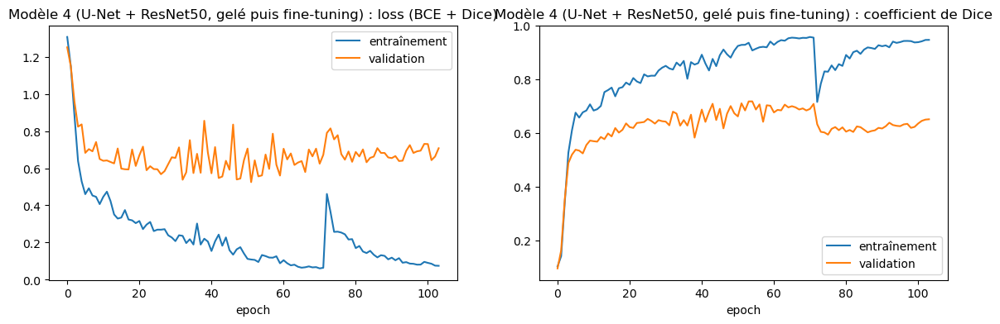

In [61]:
historique_4_complet = {cle: historique_4a[cle] + historique_4b[cle] for cle in historique_4a}
tracer_courbes(historique_4_complet, 'Modèle 4 (U-Net + ResNet50, gelé puis fine-tuning)')

historique_4 = historique_4a   # modèle 4 final = 1er temps

**Conclusions :**
- Apprentissage très rapide : dès l'epoch 5 environ, le Dice de validation dépasse 0,5, niveau que le modèle 1 n'atteint jamais.
- Pendant le 1er temps (epochs 1 à 72), le Dice de validation monte jusqu'à ≈ 0,70 et la loss de validation descend vers 0,55 à 0,65 : de loin les meilleures courbes de validation des 4 modèles.
- Écart important entre entraînement et validation (Dice ≈ 0,95 contre ≈ 0,70) : le décodeur apprend très bien les 40 images d'entraînement ; c'est du surapprentissage, mais la validation reste la meilleure.
- Au début du fine-tuning (epoch 73), la loss d'entraînement remonte brusquement (≈ 0,45) : l'encodeur dégelé reçoit d'un coup de nouvelles corrections, ce qui bouscule un réseau déjà bien réglé.
- Ensuite, le Dice de validation reste vers 0,60 à 0,65 sans retrouver son niveau du 1er temps : cela confirme le choix de garder les poids du 1er temps.

### Étape 26 : modèle 5, DeepLabV3+ avec encodeur ResNet50 pré-entraîné (transfer learning)

**Objectif :** entraîner une autre architecture de segmentation, DeepLabV3+, avec exactement le même encodeur que le modèle 4.

**Pourquoi :**
- DeepLabV3+ voit l'image à plusieurs échelles en même temps (convolutions à trous et module ASPP), mais ne garde qu'une seule connexion de raccourci, contre 3 pour le modèle 4.
- L'encodeur (ResNet50 gelé, poids ImageNet) et les réglages sont les mêmes : la comparaison 4 vs 5 mesure seulement l'effet de l'architecture.
- Un seul temps d'entraînement (encodeur gelé) : le modèle 4 a montré que le fine-tuning dégrade la validation avec 40 images.

**Méthode :**
- 26a : construire le modèle 5 (ResNet50, ASPP, petit décodeur).
- 26b : l'entraîner avec les réglages retenus (`REGLAGES`).
- 26c : tracer ses courbes.

**Ce qu'on cherche :** une loss de validation à comparer avec celle du modèle 4 (0,5252) ; on peut s'attendre à un bon niveau sur les gros obstacles, mais à plus de difficultés sur les petits (un seul raccourci).

#### Étape 26a : construire le modèle 5
**Objectif :** assembler l'encodeur ResNet50 gelé, le module ASPP et le petit décodeur de DeepLabV3+, puis vérifier la taille de sortie et le nombre de paramètres.

In [62]:
def construire_modele_5():
    entree = keras.Input(shape=(720, 1280, 3))
    x = layers.Lambda(lambda t: preprocess_input((t * ecart_type + moyenne) * 255.0))(entree)

    # Encodeur : ResNet50 pré-entraîné et gelé, comme pour le modèle 4
    resnet = ResNet50(include_top=False, weights='imagenet', input_shape=(720, 1280, 3))
    encodeur = keras.Model(resnet.input,
                           [resnet.get_layer('conv2_block3_out').output, resnet.get_layer('conv4_block6_out').output],
                           name='encodeur_resnet50')
    encodeur.trainable = False
    bas_niveau, profond = encodeur(x, training=False)          # 180 × 320 et 45 × 80

    # ASPP : convolutions à trous en parallèle (plusieurs échelles) + moyenne de toute l'image
    b0 = layers.Conv2D(256, 1, padding='same', activation='relu')(profond)
    b1 = layers.Conv2D(256, 3, padding='same', dilation_rate=6, activation='relu')(profond)
    b2 = layers.Conv2D(256, 3, padding='same', dilation_rate=12, activation='relu')(profond)
    b3 = layers.Conv2D(256, 3, padding='same', dilation_rate=18, activation='relu')(profond)
    moy = layers.GlobalAveragePooling2D(keepdims=True)(profond)
    moy = layers.Conv2D(256, 1, activation='relu')(moy)
    moy = layers.UpSampling2D(size=(45, 80))(moy)
    aspp = layers.Conv2D(256, 1, activation='relu')(layers.Concatenate()([b0, b1, b2, b3, moy]))  # 45 × 80

    # Petit décodeur : agrandir × 4 et recoller les détails de bas niveau (un seul raccourci)
    haut = layers.UpSampling2D(size=4, interpolation='bilinear')(aspp)                 # 180 × 320
    detail = layers.Conv2D(48, 1, activation='relu')(bas_niveau)
    d = bloc_conv(layers.Concatenate()([haut, detail]), 256)

    # Sortie : une valeur par pixel, agrandie × 4 jusqu'à 720 × 1280
    d = layers.Conv2D(1, 1)(d)
    d = layers.UpSampling2D(size=4, interpolation='bilinear')(d)
    sortie = layers.Activation('sigmoid')(d)
    return keras.Model(entree, sortie, name='modele_5_deeplabv3plus'), encodeur

keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

modele_5, encodeur_5 = construire_modele_5()
print("Sortie :", modele_5.output_shape)
print("Paramètres au total :", modele_5.count_params())
print("Paramètres entraînables (encodeur gelé) :", sum(int(np.prod(w.shape)) for w in modele_5.trainable_weights))

Sortie : (None, 720, 1280, 1)
Paramètres au total : 17823921
Paramètres entraînables (encodeur gelé) : 9234737


**Conclusions :**
- Sortie `(None, 720, 1280, 1)` : même taille que les masques, comme les modèles 1 à 4.
- 17 823 921 paramètres au total, dont 8 589 184 dans l'encodeur ResNet50 gelé (les mêmes que pour le modèle 4).
- 9 234 737 paramètres entraînables, environ 4 fois plus que le modèle 4 (2 228 465) : l'essentiel vient des convolutions à trous de l'ASPP, qui travaillent sur les 1 024 canaux de l'encodeur.
- Plus de paramètres à apprendre avec seulement 40 images : risque de surapprentissage plus élevé que pour le modèle 4, à surveiller sur les courbes.

#### Étape 26b : entraîner le modèle 5
**Objectif :** entraîner DeepLabV3+ avec l'encodeur gelé, dans les mêmes conditions que les autres modèles (même graine aléatoire, mêmes réglages, avec augmentation).

**Ce qu'on cherche :** la loss et le Dice de validation, à comparer avec ceux du modèle 4 (0,5252 et 0,7110).

In [63]:
historique_5, duree_5 = entrainer(modele_5, 'modele_5_deeplabv3plus', augmentation=True, **REGLAGES)

modele_5_deeplabv3plus : déjà entraîné, poids et historique rechargés (45 epochs)
Meilleure epoch : 25 | loss validation 0.4776 | Dice validation 0.7181


**Conclusions :**
- Le modèle 5 a la meilleure loss de validation des 5 modèles : 0,4776, contre 0,5252 pour le modèle 4.
- Son Dice de validation est presque identique à celui du modèle 4 (0,7181 contre 0,7110, soit + 0,007) : avec 10 images de validation, cet écart n'est pas significatif.
- L'écart de loss vient donc surtout de la BCE : DeepLabV3+ fait probablement moins d'erreurs très sûres d'elles sur le fond (fausses alertes confiantes) ; la precision, en phase 5, le vérifiera.
- Il atteint son meilleur niveau plus vite (epoch 25 contre 52 pour le modèle 4) : l'ASPP donne d'emblée une vue de toute la scène.
- À encodeur égal, l'architecture compte beaucoup moins que le pré-entraînement : + 0,31 de Dice en passant du U-Net de zéro au U-Net + ResNet50, + 0,007 en passant au DeepLabV3+.
- Reste à voir sur le test lequel détecte le mieux les petits obstacles (DSO2), puisque DeepLabV3+ n'a qu'un seul raccourci.

#### Étape 26c : tracer les courbes du modèle 5
**Objectif :** vérifier comment DeepLabV3+ apprend et comparer l'écart entre entraînement et validation avec celui du modèle 4.

**Ce qu'on cherche :** une montée rapide du Dice de validation vers 0,70, et un écart entre entraînement et validation peut-être plus grand que pour le modèle 4, puisqu'il a 4 fois plus de paramètres entraînables.

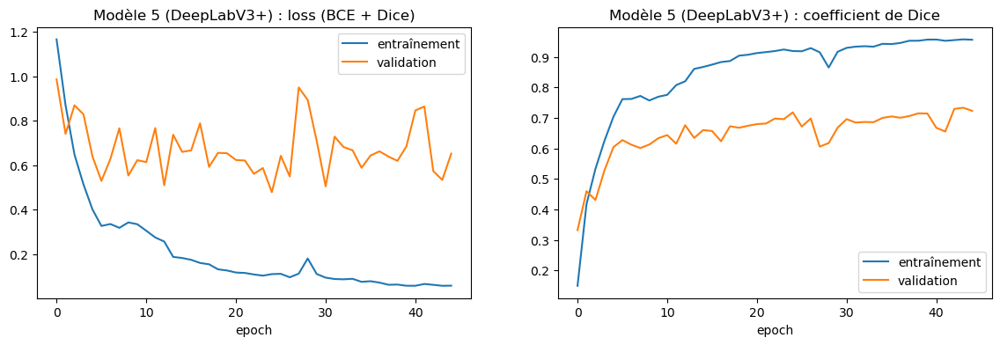

In [64]:
tracer_courbes(historique_5, 'Modèle 5 (DeepLabV3+)')

**Conclusions :**
- Apprentissage le plus rapide des 5 modèles : Dice d'entraînement ≈ 0,76 dès l'epoch 5, Dice de validation ≈ 0,60.
- Le Dice de validation monte ensuite lentement jusqu'à ≈ 0,72-0,73 en fin d'entraînement.
- La loss de validation est très instable (entre ≈ 0,48 et ≈ 0,95), avec des pics nets vers les epochs 27-28 et 41-42 : plus agitée que celle du modèle 4.
- La meilleure loss (0,4776, epoch 25) est un creux isolé entre deux zones plus hautes : le choix des poids dépend en partie du hasard des 10 images de validation. Le test dira si ce modèle est vraiment meilleur que le modèle 4.
- Écart fort entre entraînement et validation (Dice ≈ 0,95 contre ≈ 0,72) : surapprentissage comparable à celui du modèle 4, cohérent avec ses 9,2 millions de paramètres entraînables.

### Étape 27 : comparer les loss des 5 modèles

**Objectif :** afficher les courbes de validation des 5 modèles sur un même graphique, puis résumer leurs résultats dans un tableau.

**Pourquoi :**
- C'est la comparaison demandée : les 5 modèles ont été entraînés dans les mêmes conditions (même découpage, même perte, mêmes réglages, même early stopping), leurs loss sont donc comparables.
- Un même graphique montre d'un coup quel modèle apprend le plus vite, lequel va le plus bas et lequel est le plus stable.

**Méthode :**
- 27a : recharger les historiques sauvegardés sur Google Drive et tracer la loss et le Dice de validation des 5 modèles.
- 27b : tableau récapitulatif (meilleure epoch, loss et Dice de validation, écart entre entraînement et validation).

**Ce qu'on cherche :** deux groupes nets (modèles de zéro 1 à 3, modèles pré-entraînés 4 et 5), et le classement des modèles sur la validation.

#### Étape 27a : courbes de validation des 5 modèles
**Objectif :** superposer les courbes de validation des 5 modèles, à partir des historiques sauvegardés sur Google Drive.

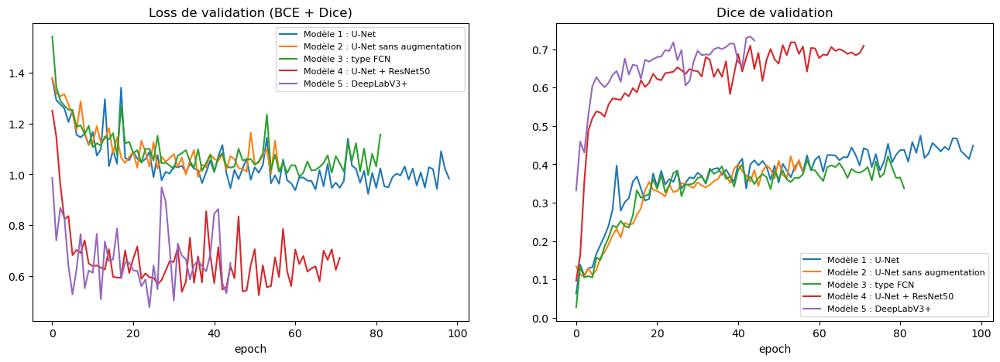

In [65]:
noms_modeles = {
    'Modèle 1 : U-Net': 'grid_lr0.0001_bs2',
    'Modèle 2 : U-Net sans augmentation': 'modele_2_unet_sans_aug',
    'Modèle 3 : type FCN': 'modele_3_fcn',
    'Modèle 4 : U-Net + ResNet50': 'modele_4_unet_resnet50_gele',
    'Modèle 5 : DeepLabV3+': 'modele_5_deeplabv3plus',
}

historiques = {}
for titre, fichier in noms_modeles.items():
    with open(os.path.join(DOSSIER_MODELES, fichier + '_historique.json')) as f:
        historiques[titre] = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for titre, h in historiques.items():
    axes[0].plot(h['val_loss'], label=titre)
    axes[1].plot(h['val_coef_dice'], label=titre)
axes[0].set_title('Loss de validation (BCE + Dice)')
axes[1].set_title('Dice de validation')
for a in axes:
    a.set_xlabel('epoch')
    a.legend(fontsize=8)
plt.show()

**Conclusions :**
- Deux groupes très nets, sur les deux graphiques :
  - modèles pré-entraînés (4 et 5) : loss de validation entre ≈ 0,5 et 0,8, Dice entre ≈ 0,6 et 0,73 ;
  - modèles construits de zéro (1, 2, 3) : loss entre ≈ 0,95 et 1,2, Dice entre ≈ 0,3 et 0,47.
- L'écart entre les deux groupes (≈ 0,3 de Dice) est bien plus grand que les écarts à l'intérieur de chaque groupe : le pré-entraînement est le facteur décisif.
- Les modèles pré-entraînés démarrent aussi bien plus vite : Dice ≈ 0,5 à 0,6 dès l'epoch 5, niveau que les modèles de zéro n'atteignent jamais.
- Dans le groupe « de zéro », le modèle 1 (U-Net avec augmentation) finit un peu au-dessus (≈ 0,45) et apprend plus longtemps ; les modèles 2 (sans augmentation) et 3 (sans raccourcis) plafonnent vers 0,38-0,40.
- Dans le groupe pré-entraîné, le modèle 5 monte le plus vite au début et finit un peu plus haut (≈ 0,72), mais les courbes des modèles 4 et 5 restent très proches et oscillent toutes les deux.

#### Étape 27b : tableau récapitulatif des 5 modèles
**Objectif :** réunir dans un seul tableau, pour chaque modèle, la meilleure epoch, la loss et le Dice de validation, l'écart entre entraînement et validation, le nombre de paramètres entraînables et la durée d'entraînement.

**Ce qu'on cherche :** le classement des modèles sur la validation, et l'écart de Dice entre entraînement et validation comme mesure du surapprentissage.

In [66]:
# Relevés aux étapes 20 à 26
parametres_entraines = {'Modèle 1 : U-Net': 1962625, 'Modèle 2 : U-Net sans augmentation': 1962625,
                        'Modèle 3 : type FCN': 1766785, 'Modèle 4 : U-Net + ResNet50': 2228465,
                        'Modèle 5 : DeepLabV3+': 9234737}
durees_min = {'Modèle 1 : U-Net': 9.5, 'Modèle 2 : U-Net sans augmentation': 5.6,
              'Modèle 3 : type FCN': 7.1, 'Modèle 4 : U-Net + ResNet50': 8.6,
              'Modèle 5 : DeepLabV3+': 6.7}

lignes = []
for titre, h in historiques.items():
    m = int(np.argmin(h['val_loss']))
    lignes.append({'modèle': titre,
                   'paramètres entraînés': parametres_entraines[titre],
                   'epochs': len(h['loss']),
                   'meilleure epoch': m + 1,
                   'loss validation': round(h['val_loss'][m], 4),
                   'Dice validation': round(h['val_coef_dice'][m], 4),
                   'Dice entraînement': round(h['coef_dice'][m], 4),
                   'écart Dice': round(h['coef_dice'][m] - h['val_coef_dice'][m], 4),
                   'durée (min)': durees_min[titre]})

df_comparaison = pd.DataFrame(lignes).sort_values('loss validation').reset_index(drop=True)
df_comparaison.to_csv(os.path.join(DOSSIER_MODELES, 'comparaison_modeles.csv'), index=False)
df_comparaison

,modèle,paramètres entraînés,epochs,meilleure epoch,loss validation,Dice validation,Dice entraînement,écart Dice,durée (min)
0,Modèle 5 : DeepLabV3+,9234737,45,25,0.4776,0.7181,0.9192,0.2010,6.7
1,Modèle 4 : U-Net + ResNet50,2228465,72,52,0.5252,0.7110,0.9286,0.2176,8.6
2,Modèle 1 : U-Net,1962625,99,79,0.9231,0.4053,0.5655,0.1602,9.5
3,Modèle 2 : U-Net sans augmentation,1962625,57,37,0.9898,0.3802,0.4801,0.1000,5.6
4,Modèle 3 : type FCN,1766785,82,62,0.9906,0.3567,0.5072,0.1505,7.1


**Conclusions :**
- Classement sur la validation : 5 > 4 > 1 > 2 > 3, avec deux groupes nets : modèles pré-entraînés vers 0,71-0,72 de Dice, modèles construits de zéro entre 0,36 et 0,41.
- Les deux meilleurs modèles sont presque à égalité en Dice (0,7181 contre 0,7110) ; le modèle 4 atteint ce niveau avec 4 fois moins de paramètres entraînés (2,2 contre 9,2 millions).
- Entre les modèles de zéro, l'ordre confirme les deux ablations : retirer l'augmentation (modèle 2) ou les raccourcis (modèle 3) fait baisser le Dice.
- Les modèles pré-entraînés ont le plus grand écart entre entraînement et validation (≈ 0,20-0,22) : ils apprennent presque parfaitement les 40 images (Dice ≈ 0,92-0,93), mais restent de loin les meilleurs en validation.
- Attention : l'écart est mesuré à la meilleure epoch. Le modèle 2 a le plus petit (0,10), car sa meilleure epoch arrive tôt (37), avant qu'il ait appris ses images par cœur ; ses courbes (étape 23b) montraient pourtant un surapprentissage plus précoce que celui du modèle 1.
- Tous les entraînements durent moins de 10 minutes en pleine résolution sur le GPU T4.

# 5. Evaluation

**Objectif :** mesurer la qualité des 5 modèles sur les 10 images de test, qu'aucun modèle n'a jamais vues, ni pendant l'entraînement ni pour le choix des réglages.

**Méthode :**
- Étape 28 (DSO1) : prédire chaque pixel du test (seuil 0,5), puis calculer precision, recall, F1, IoU et Dice pour chaque modèle.
- Étape 29 (DSO2) : vérifier, obstacle par obstacle, lesquels sont détectés, et calculer le recall par groupe de taille (< 0,1 %, 0,1–1 %, 1–5 %, > 5 % de l'image).

### Étape 28 : métriques par pixel sur le test (DSO1)

**Objectif :** savoir, pour chaque modèle, quelle part des pixels d'obstacle il retrouve et quelle part de ses alertes est juste, sur des images nouvelles.

**Pourquoi :** la validation a servi à choisir les réglages et les meilleurs poids ; seul le test donne une mesure honnête de la qualité finale (BO1).

**Méthode :**
- 28a : standardiser le test, recharger les meilleurs poids de chaque modèle depuis Google Drive et prédire les 10 images.
- 28b : appliquer le seuil 0,5 et calculer les 5 métriques par modèle.

**Ce qu'on cherche :** un classement sur le test proche de celui de la validation, et des chiffres de precision et de recall pour comprendre le type d'erreurs (fausses alertes ou obstacles ratés).

#### Étape 28a : prédire les images de test avec les 5 modèles
**Objectif :** reconstruire chaque modèle, recharger ses meilleurs poids sauvegardés et calculer, pour chaque pixel des 10 images de test, la probabilité d'obstacle.

In [67]:
X_test_std = standardiser(X_test).astype(np.float32)

modeles_a_evaluer = {
    'Modèle 1 : U-Net': (lambda: construire_modele_1(filtres=16), 'grid_lr0.0001_bs2'),
    'Modèle 2 : U-Net sans augmentation': (lambda: construire_modele_1(filtres=16), 'modele_2_unet_sans_aug'),
    'Modèle 3 : type FCN': (lambda: construire_modele_3(filtres=16), 'modele_3_fcn'),
    'Modèle 4 : U-Net + ResNet50': (lambda: construire_modele_4()[0], 'modele_4_unet_resnet50_gele'),
    'Modèle 5 : DeepLabV3+': (lambda: construire_modele_5()[0], 'modele_5_deeplabv3plus'),
}

probas_test = {}
for titre, (construire, fichier) in modeles_a_evaluer.items():
    keras.backend.clear_session()
    modele = construire()
    modele.load_weights(os.path.join(DOSSIER_MODELES, fichier + '.weights.h5'))
    probas_test[titre] = modele.predict(X_test_std, batch_size=2, verbose=0)[..., 0]
    print(f"{titre} : {probas_test[titre].shape} | probabilités de {probas_test[titre].min():.3f} à {probas_test[titre].max():.3f}")
    del modele

print("Masques de test :", Y_test.shape, np.unique(Y_test))

Modèle 1 : U-Net : (10, 720, 1280) | probabilités de 0.000 à 0.996
Modèle 2 : U-Net sans augmentation : (10, 720, 1280) | probabilités de 0.000 à 0.998
Modèle 3 : type FCN : (10, 720, 1280) | probabilités de 0.000 à 0.998
Modèle 4 : U-Net + ResNet50 : (10, 720, 1280) | probabilités de 0.000 à 1.000
Modèle 5 : DeepLabV3+ : (10, 720, 1280) | probabilités de 0.000 à 1.000
Masques de test : (10, 720, 1280) [0 1]


**Conclusions :**
- Les 5 modèles ont été rechargés depuis le dossier `RoadAnomaly_modeles` et ont prédit les 10 images de test : une carte `(720, 1280)` par image, comme les masques `(10, 720, 1280)`.
- Probabilités entre 0 et 1 pour tous les modèles : les modèles pré-entraînés (4 et 5) vont jusqu'à 1,000, ils sont plus sûrs d'eux sur certains pixels que les modèles construits de zéro (0,996 à 0,998).
- Masques de test en `[0 1]` : on peut comparer pixel par pixel la prédiction (après seuil) et la vérité.

#### Étape 28b : calculer les 5 métriques sur le test
**Objectif :** transformer chaque probabilité en réponse 0 / 1 (seuil 0,5), puis compter, pour chaque modèle, les pixels bien détectés, les fausses alertes et les obstacles ratés.

**Les métriques :**
- **Precision** : parmi les pixels annoncés « obstacle », la part qui en est vraiment (peu de fausses alertes = precision haute).
- **Recall** : parmi les vrais pixels d'obstacle, la part retrouvée (peu d'obstacles ratés = recall haut).
- **F1** : la moyenne harmonique des deux, calculée sur tous les pixels des 10 images.
- **IoU** : pixels en commun ÷ pixels de la prédiction ou de la vérité (zone commune ÷ zone totale).
- **Dice moyen** : Dice calculé image par image, puis moyenné : chaque image compte autant, quelle que soit la taille de son obstacle.

**Ce qu'on cherche :** le même classement que sur la validation (modèles 4 et 5 devant), et l'équilibre entre precision et recall pour chaque modèle.

In [68]:
def metriques(proba, vrai, seuil=0.5):
    pred = proba >= seuil
    vrai = vrai.astype(bool)
    vp = np.logical_and(pred, vrai).sum()    # vrais positifs : obstacle prédit et réel
    fp = np.logical_and(pred, ~vrai).sum()   # faux positifs : fausses alertes
    fn = np.logical_and(~pred, vrai).sum()   # faux négatifs : obstacle raté
    precision = vp / (vp + fp) if vp + fp > 0 else 0.0
    recall = vp / (vp + fn)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    iou = vp / (vp + fp + fn)
    dice_images = [2 * np.logical_and(p, v).sum() / (p.sum() + v.sum()) for p, v in zip(pred, vrai)]
    return precision, recall, f1, iou, float(np.mean(dice_images))

lignes = []
for titre, proba in probas_test.items():
    precision, recall, f1, iou, dice = metriques(proba, Y_test)
    lignes.append({'modèle': titre, 'precision': round(precision, 4), 'recall': round(recall, 4),
                   'F1': round(f1, 4), 'IoU': round(iou, 4), 'Dice moyen': round(dice, 4)})

df_test = pd.DataFrame(lignes).sort_values('F1', ascending=False).reset_index(drop=True)
df_test.to_csv(os.path.join(DOSSIER_MODELES, 'metriques_test.csv'), index=False)
df_test

,modèle,precision,recall,F1,IoU,Dice moyen
0,Modèle 5 : DeepLabV3+,0.8314,0.7625,0.7954,0.6604,0.7775
1,Modèle 4 : U-Net + ResNet50,0.8731,0.6155,0.7220,0.5649,0.7075
2,Modèle 1 : U-Net,0.3966,0.5262,0.4523,0.2922,0.4238
3,Modèle 2 : U-Net sans augmentation,0.3917,0.3033,0.3419,0.2062,0.3654
4,Modèle 3 : type FCN,0.3529,0.2719,0.3071,0.1814,0.3162


**Conclusions :**
- Même classement que sur la validation : 5 > 4 > 1 > 2 > 3. Le choix des modèles fait sur la validation est confirmé sur des images jamais vues.
- Le modèle 5 (DeepLabV3+) est le meilleur sur 4 métriques sur 5 : F1 0,7954, IoU 0,6604, Dice moyen 0,7775, et surtout le meilleur recall (0,7625 : il retrouve 76 % des pixels d'obstacle).
- Le modèle 4 (U-Net + ResNet50) a la meilleure precision (0,8731 : 87 % de ses alertes sont justes), mais rate plus d'obstacles (recall 0,6155). Pour un véhicule, rater un obstacle est plus grave qu'une fausse alerte : le modèle 5 est le plus adapté.
- L'écart entre les modèles 5 et 4 est plus net sur le test (F1 + 0,07) que sur la validation (Dice + 0,007).
- Modèles construits de zéro : precision ≈ 0,35-0,40, soit environ 6 alertes sur 10 fausses, et F1 entre 0,31 et 0,45. Le transfer learning fait presque doubler le F1.
- Les deux ablations se confirment, plus nettement que sur la validation : sans augmentation, F1 0,3419 au lieu de 0,4523 (− 0,11) ; sans raccourcis, 0,3071 (− 0,15).
- Pour les trois meilleurs modèles, le Dice moyen par image est un peu plus bas que le F1 global : ils réussissent un peu moins bien les images à petits obstacles (à vérifier à l'étape 29).
- Limite : 10 images de test seulement ; les chiffres sont indicatifs, un autre découpage donnerait des valeurs un peu différentes.

### Étape 29 : détection selon la taille des obstacles (DSO2)

**Objectif :** vérifier, obstacle par obstacle, lesquels sont détectés et lesquels sont ratés, puis calculer le recall par groupe de taille.

**Pourquoi :**
- BO2 demande de détecter les obstacles lointains. Le dataset ne donne pas la distance, mais un obstacle lointain apparaît petit : la taille dans l'image sert de mesure indirecte.
- Les métriques par pixel (étape 28) sont dominées par les gros obstacles, qui ont beaucoup de pixels ; ici, chaque obstacle compte pour un, quelle que soit sa taille.

**Méthode :**
- 29a : lister les obstacles des images de test grâce aux masques d'instances (tableau `df_objets` de l'étape 12).
- 29b : pour chaque obstacle et chaque modèle, mesurer la part de ses pixels prédits « obstacle » ; l'obstacle est compté comme détecté si au moins 50 % de ses pixels le sont.
- 29c : recall par groupe de taille (< 0,1 %, 0,1–1 %, 1–5 %, > 5 % de l'image), en tableau et en graphique.

**Ce qu'on cherche :** un recall qui baisse pour les petits obstacles, et quel modèle détecte le mieux les obstacles lointains.

#### Étape 29a : lister les obstacles des images de test
**Objectif :** retrouver, parmi les 201 obstacles de l'étape 12, ceux des 10 images de test, et compter combien il y en a dans chaque groupe de taille.

In [69]:
noms_test = df.loc[df['ensemble'] == 'test', 'nom'].tolist()
objets_test = df_objets[df_objets['nom'].isin(noms_test)].copy()

print("Images de test :", len(noms_test))
print("Images de test avec masque d'instances :", objets_test['nom'].nunique())
print("Obstacles à évaluer :", len(objets_test))
objets_test['taille'].value_counts().sort_index()

Images de test : 10
Images de test avec masque d'instances : 7
Obstacles à évaluer : 15


taille
< 0,1 %      0
0,1 – 1 %    8
1 – 5 %      5
> 5 %        2
Name: count, dtype: int64

**Conclusions :**
- Les images de test contiennent 15 obstacles évaluables : 0 de moins de 0,1 % de l'image, 8 de 0,1 à 1 %, 5 de 1 à 5 %, 2 de plus de 5 %.
- Le groupe des tout petits obstacles (< 0,1 %), le plus intéressant pour les obstacles lointains (BO2), est vide dans le test : les 63 obstacles de ce groupe sont tous dans d'autres images.
- Avec 15 obstacles, chaque obstacle pèse beaucoup : dans le groupe > 5 %, un seul obstacle raté fait passer le recall de 100 % à 50 %.
- Cause : le découpage de l'étape 15 est stratifié par catégorie d'image, pas par taille d'obstacle ; avec 60 images, on ne peut pas équilibrer les deux.
- Pour évaluer quand même les tout petits obstacles, on ajoute en complément les 10 images de validation, jamais apprises par les modèles (elles ont seulement servi à choisir les meilleurs poids). Le test reste le résultat principal.

#### Étape 29b : prédire aussi les images de validation
**Objectif :** obtenir les probabilités des 5 modèles sur les 10 images de validation, pour évaluer aussi les obstacles qu'elles contiennent, en particulier les tout petits.

In [70]:
noms_val = df.loc[df['ensemble'] == 'validation', 'nom'].tolist()
objets_val = df_objets[df_objets['nom'].isin(noms_val)].copy()

probas_val = {}
for titre, (construire, fichier) in modeles_a_evaluer.items():
    keras.backend.clear_session()
    modele = construire()
    modele.load_weights(os.path.join(DOSSIER_MODELES, fichier + '.weights.h5'))
    probas_val[titre] = modele.predict(X_val_std, batch_size=2, verbose=0)[..., 0]
    print(f"{titre} : {probas_val[titre].shape}")
    del modele

print("\nObstacles de validation à évaluer :", len(objets_val))
objets_val['taille'].value_counts().sort_index()

Modèle 1 : U-Net : (10, 720, 1280)
Modèle 2 : U-Net sans augmentation : (10, 720, 1280)
Modèle 3 : type FCN : (10, 720, 1280)
Modèle 4 : U-Net + ResNet50 : (10, 720, 1280)
Modèle 5 : DeepLabV3+ : (10, 720, 1280)

Obstacles de validation à évaluer : 34


taille
< 0,1 %       9
0,1 – 1 %    17
1 – 5 %       5
> 5 %         3
Name: count, dtype: int64

**Conclusions :**
- Les 5 modèles ont prédit les 10 images de validation `(10, 720, 1280)`.
- La validation contient 34 obstacles évaluables : 9 de moins de 0,1 % de l'image, 17 de 0,1 à 1 %, 5 de 1 à 5 %, 3 de plus de 5 %.
- Elle apporte les 9 tout petits obstacles absents du test, et deux fois plus de petits obstacles (17 contre 8) : elle permet d'évaluer les obstacles lointains.
- Réserve : la validation a servi à choisir les meilleurs poids (early stopping) ; ses résultats peuvent être un peu optimistes. Ils sont présentés à part, le test reste le résultat principal.
- Les groupes restent petits (2 à 17 obstacles) : chaque recall est indicatif.

#### Étape 29c : recall par taille d'obstacle
**Objectif :** pour chaque obstacle et chaque modèle, calculer la part de ses pixels prédits « obstacle » (sa couverture), le compter comme détecté si cette part atteint 50 %, puis calculer le recall dans chaque groupe de taille, sur le test et sur la validation.

**Ce qu'on cherche :** un recall plus bas pour les petits obstacles, et le modèle qui détecte le mieux les obstacles lointains (< 0,1 % et 0,1–1 %).

In [71]:
def couverture_obstacles(objets, noms, probas, seuil=0.5):
    lignes = []
    for _, obj in objets.iterrows():
        i = noms.index(obj['nom'])
        instances = np.array(Image.open(os.path.join(FRAMES_DIR, obj['nom'] + '.labels', 'labels_instance.png')))
        zone = instances == obj['numero']
        ligne = {'nom': obj['nom'], 'numero': obj['numero'], 'taille': obj['taille']}
        for titre, proba in probas.items():
            ligne[titre] = float((proba[i][zone] >= seuil).mean())
        lignes.append(ligne)
    couv = pd.DataFrame(lignes)
    couv['taille'] = pd.Categorical(couv['taille'], categories=df_objets['taille'].cat.categories, ordered=True)
    return couv

def recall_par_taille(couv, seuil_detection=0.5):
    titres = list(probas_test.keys())
    detecte = (couv[titres] >= seuil_detection).astype(float)
    detecte['taille'] = couv['taille']
    tableau = detecte.groupby('taille', observed=False)[titres].mean().T
    tableau['tous'] = detecte[titres].mean()
    effectifs = couv['taille'].value_counts().sort_index()
    tableau.columns = [f"{c} ({n})" for c, n in zip(effectifs.index, effectifs.values)] + [f"tous ({len(couv)})"]
    return tableau.round(2)

couv_test = couverture_obstacles(objets_test, noms_test, probas_test)
couv_val = couverture_obstacles(objets_val, noms_val, probas_val)

recall_test = recall_par_taille(couv_test)
recall_val = recall_par_taille(couv_val)
recall_test.to_csv(os.path.join(DOSSIER_MODELES, 'recall_taille_test.csv'))
recall_val.to_csv(os.path.join(DOSSIER_MODELES, 'recall_taille_validation.csv'))

print("Recall par taille d'obstacle — TEST (résultat principal), effectif entre parenthèses :")
display(recall_test)
print("Recall par taille d'obstacle — VALIDATION (complément) :")
display(recall_val)

Recall par taille d'obstacle — TEST (résultat principal), effectif entre parenthèses :


,"< 0,1 % (0)","0,1 – 1 % (8)",1 – 5 % (5),> 5 % (2),tous (15)
Modèle 1 : U-Net,NaN,0.62,0.8,1.0,0.73
Modèle 2 : U-Net sans augmentation,NaN,0.50,0.2,0.5,0.40
Modèle 3 : type FCN,NaN,0.50,0.4,1.0,0.53
Modèle 4 : U-Net + ResNet50,NaN,1.00,0.6,1.0,0.87
Modèle 5 : DeepLabV3+,NaN,1.00,1.0,1.0,1.00


Recall par taille d'obstacle — VALIDATION (complément) :


,"< 0,1 % (9)","0,1 – 1 % (17)",1 – 5 % (5),> 5 % (3),tous (34)
Modèle 1 : U-Net,0.78,0.88,1.0,0.67,0.85
Modèle 2 : U-Net sans augmentation,0.56,0.65,0.4,0.33,0.56
Modèle 3 : type FCN,0.89,0.65,0.8,0.33,0.71
Modèle 4 : U-Net + ResNet50,0.44,0.94,1.0,0.67,0.79
Modèle 5 : DeepLabV3+,0.22,0.94,1.0,0.67,0.74


**Conclusions :**
- Sur le test, DeepLabV3+ détecte les 15 obstacles (100 %), y compris les 8 petits (0,1-1 %) ; le U-Net + ResNet50 en détecte 13 (87 %) et rate 2 obstacles moyens (1-5 %).
- Les petits obstacles (0,1-1 %) sont bien détectés par les deux modèles pré-entraînés : 100 % sur le test, 94 % sur la validation.
- Pour les tout petits obstacles (< 0,1 %, validation seulement), l'ordre s'inverse : DeepLabV3+ n'en détecte que 2 sur 9 (22 %) et le U-Net + ResNet50 4 sur 9 (44 %), contre 7 (78 %) pour le U-Net de zéro et 8 (89 %) pour le type FCN.
- Explication : le U-Net de zéro garde un raccourci en pleine résolution (720 × 1280) ; DeepLabV3+ calcule sa sortie à 180 × 320 puis l'agrandit × 4, si bien qu'un obstacle de 20 × 20 pixels n'y fait plus que 5 × 5 pixels ; le raccourci le plus fin du U-Net + ResNet50 est à 360 × 640.
- Prudence pour les modèles de zéro : le recall par obstacle ne compte pas les fausses alertes. Avec une precision de ≈ 0,35-0,40 (étape 28b), ils colorient de grandes zones qui recouvrent parfois les tout petits obstacles par hasard ; les 89 % du type FCN, qui n'a aucun raccourci, en sont un indice.
- La data augmentation aide à toutes les tailles : le modèle 2 (sans) est en dessous du modèle 1 dans tous les groupes, sur le test comme sur la validation.
- Gros obstacles (> 5 %, validation) : 67 % au mieux, car l'un des 3 est couvert à moins de 50 % par tous les modèles.
- Réponse à BO2 : les obstacles lointains de 0,1 à 1 % de l'image sont très bien détectés par les modèles pré-entraînés, mais les tout petits (< 0,1 %) restent leur point faible. Il faudrait combiner la précision des modèles pré-entraînés et la pleine résolution du U-Net.
- Limites : 15 obstacles de test, aucun tout petit, et des groupes de 2 à 17 obstacles ; les résultats de la validation peuvent être un peu optimistes (elle a servi à l'early stopping).

#### Étape 29d : graphique du recall par taille
**Objectif :** visualiser, pour le test et la validation, la part des obstacles détectés par chaque modèle selon leur taille.

**Ce qu'on cherche :** voir d'un coup d'œil l'inversion entre modèles sur les tout petits obstacles.

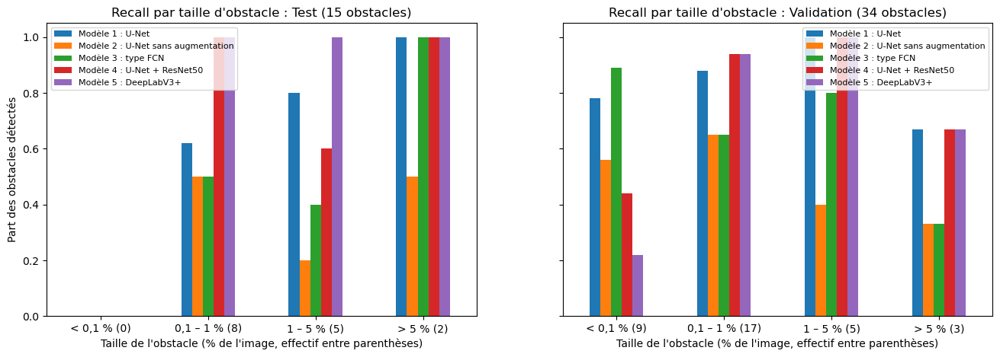

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for a, (tableau, titre) in zip(axes, [(recall_test, 'Test (15 obstacles)'), (recall_val, 'Validation (34 obstacles)')]):
    tableau.iloc[:, :-1].T.plot(kind='bar', ax=a, rot=0)
    a.set_title("Recall par taille d'obstacle : " + titre)
    a.set_xlabel("Taille de l'obstacle (% de l'image, effectif entre parenthèses)")
    a.set_ylabel('Part des obstacles détectés')
    a.set_ylim(0, 1.05)
    a.legend(fontsize=8)
plt.show()

**Conclusions :**
- Sur le test, les barres des modèles pré-entraînés (rouge et violet) dominent à toutes les tailles ; DeepLabV3+ atteint 1,0 partout.
- Sur la validation, le graphique montre nettement l'inversion pour les tout petits obstacles (< 0,1 %) : les barres des modèles de zéro sont les plus hautes, celle de DeepLabV3+ la plus basse (0,22).
- Dès 0,1 % de l'image, les modèles pré-entraînés repassent devant.

# 6. Analyse des résultats

**Objectif :** comprendre, en regardant les prédictions, où et pourquoi les modèles réussissent ou se trompent, puis résumer les forces et les limites du projet.

**Méthode :**
- Étape 30 : visualiser les prédictions sur des images de test (bons cas, cas moyens, cas difficiles).
- Étape 31 : forces, limites et améliorations possibles.

### Étape 30 : visualiser les prédictions

**Objectif :** afficher, sur des images de test, ce que chaque modèle détecte, ce qu'il rate et où il donne de fausses alertes.

**Pourquoi :** les métriques donnent un score global, mais ne disent pas où le modèle se trompe : sur les bords d'un obstacle, sur un petit objet lointain, sur une ombre ou un panneau…

**Méthode :**
- 30a : choisir 3 images de test selon le Dice de DeepLabV3+ (la meilleure, une moyenne, la plus difficile) et comparer les prédictions de 3 modèles : U-Net de zéro, U-Net + ResNet50, DeepLabV3+.
- Code couleur : vert = obstacle bien détecté, rouge = fausse alerte, bleu = obstacle raté.

**Ce qu'on cherche :** le type d'erreur de chaque modèle (fausses alertes ou obstacles ratés), et sur quels éléments de la scène elles se produisent.

#### Étape 30a : bons cas et cas difficiles sur le test
**Objectif :** comparer côte à côte la photo et les prédictions de 3 modèles sur la meilleure image, une image moyenne et la plus difficile pour DeepLabV3+.

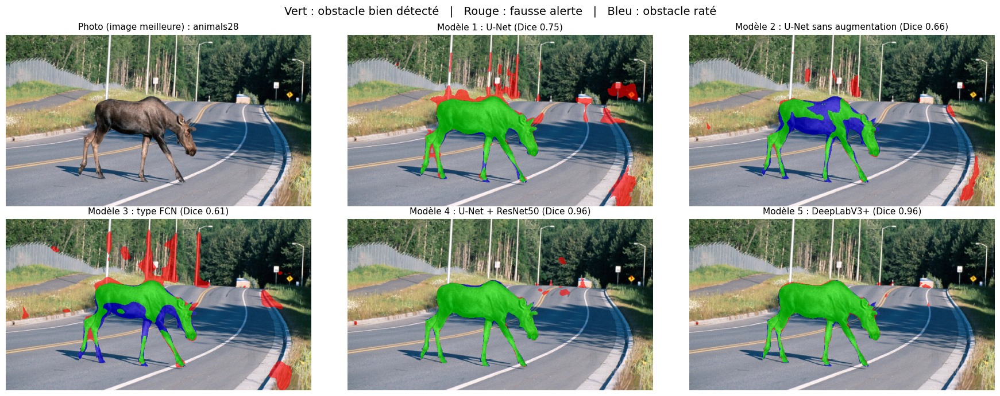

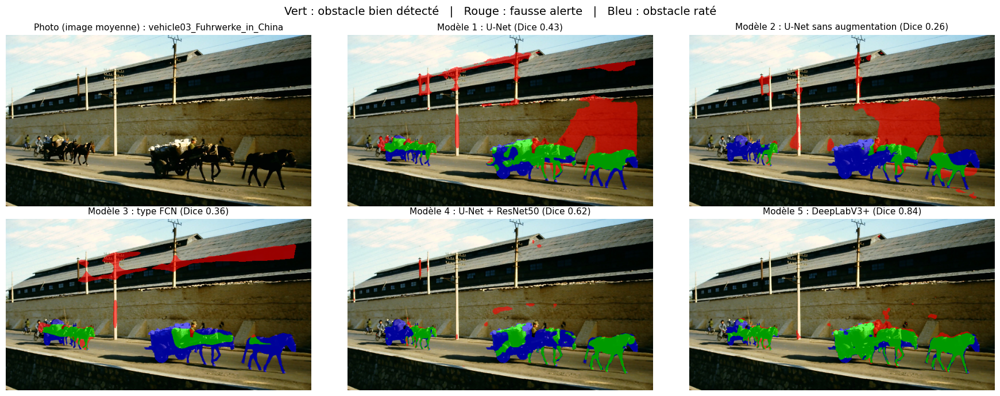

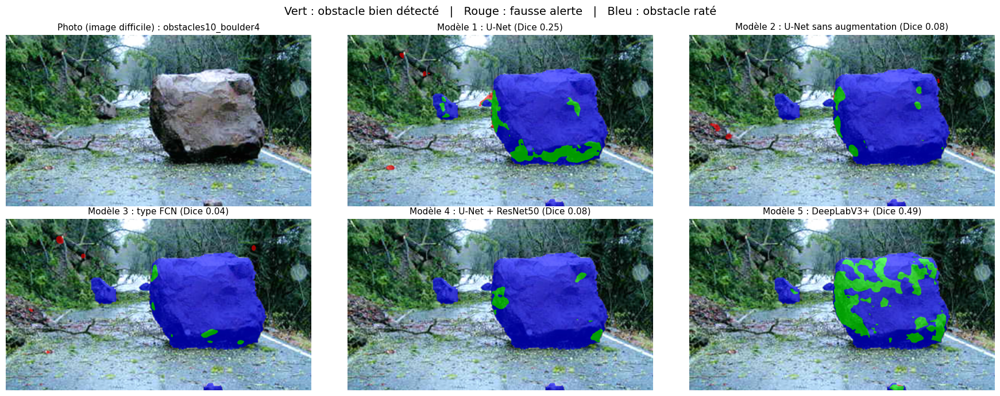

In [73]:
del probas_val          # prédictions de la validation : plus utiles, on libère la mémoire
import gc; gc.collect()

def superposer(photo, pred, vrai):
    image = photo.copy()
    for zone, couleur in [(pred & vrai, [0, 1, 0]), (pred & ~vrai, [1, 0, 0]), (~pred & vrai, [0, 0, 1])]:
        image[zone] = 0.4 * image[zone] + 0.6 * np.array(couleur)
    return image

def dice_image(pred, vrai):
    return 2 * (pred & vrai).sum() / (pred.sum() + vrai.sum())

vrai_test = Y_test.astype(bool)
pred5 = probas_test['Modèle 5 : DeepLabV3+'] >= 0.5
dice5 = np.array([dice_image(p, v) for p, v in zip(pred5, vrai_test)])
ordre = np.argsort(dice5)
choix = {'meilleure': ordre[-1], 'moyenne': ordre[len(ordre) // 2], 'difficile': ordre[0]}

DOSSIER_FIGURES = os.path.join(DOSSIER_PROJET, 'figures')
os.makedirs(DOSSIER_FIGURES, exist_ok=True)

for rang, i in choix.items():
    photo = X_test[i][::2, ::2]          # affichage en demi-résolution (640 × 360)
    vrai = vrai_test[i][::2, ::2]
    fig, axes = plt.subplots(2, 3, figsize=(18, 7))
    axes = axes.ravel()
    axes[0].imshow(photo)
    axes[0].set_title(f"Photo (image {rang}) : {noms_test[i][:40]}", fontsize=11)
    for a, titre in zip(axes[1:], probas_test.keys()):
        pred_complet = probas_test[titre][i] >= 0.5
        pred = pred_complet[::2, ::2]
        a.imshow(superposer(photo, pred, vrai))
        a.set_title(f"{titre} (Dice {dice_image(pred_complet, vrai_test[i]):.2f})", fontsize=11)
    for a in axes:
        a.axis('off')
    fig.suptitle("Vert : obstacle bien détecté   |   Rouge : fausse alerte   |   Bleu : obstacle raté", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(DOSSIER_FIGURES, f'predictions_{rang}.png'), dpi=100)
    plt.show()
    plt.close(fig)

**Légende :** 🟩 <span style="color:green">**vert = obstacle bien détecté**</span> | 🟥 <span style="color:red">**rouge = fausse alerte**</span> | 🟦 <span style="color:blue">**bleu = obstacle raté**</span>

| Image | M1 | M2 | M3 | M4 | M5 |
| --- | --- | --- | --- | --- | --- |
| Meilleure : élan | 0,75 | 0,66 | 0,61 | 0,96 | 0,96 |
| Moyenne : charrettes | 0,43 | 0,26 | 0,36 | 0,62 | 0,84 |
| Difficile : rocher | 0,25 | 0,08 | 0,04 | 0,08 | 0,49 |

**Conclusions :**
- Modèles de zéro (1, 2, 3) : beaucoup de 🟥, sur les poteaux, les arbres, le bord de route et le mur.
- Modèles pré-entraînés (4, 5) : presque pas de 🟥, ils reconnaissent les vrais objets.
- Élan : modèles 4 et 5 presque parfaits (0,96).
- Charrettes : DeepLabV3+ est le seul à couvrir les charrettes entières (0,84).
- Rocher : raté par tous (surtout 🟦), sauf en partie par DeepLabV3+ (0,49) ; il se confond avec la route grise.
- Le rocher n'a pas de masque d'instances : il n'est pas compté à l'étape 29.

#### Étape 28c : erreurs de chaque modèle
**Objectif :** compter les pixels bien classés et les deux types d'erreur (fausses alertes, obstacles ratés).

**Ce qu'on cherche :** le FPR (% du fond signalé à tort) et le FNR (% des obstacles ratés) de chaque modèle.

In [74]:
lignes = []
vrai = Y_test.astype(bool)
for titre, proba in probas_test.items():
    pred = proba >= 0.5
    vp, fp = (pred & vrai).sum(), (pred & ~vrai).sum()
    fn, vn = (~pred & vrai).sum(), (~pred & ~vrai).sum()
    lignes.append({'modèle': titre, 'VP': vp, 'FP': fp, 'FN': fn, 'VN': vn,
                   'FPR (%)': round(100 * fp / (fp + vn), 2),
                   'FNR (%)': round(100 * fn / (fn + vp), 2)})
df_erreurs = pd.DataFrame(lignes)
df_erreurs.to_csv(os.path.join(DOSSIER_MODELES, 'erreurs_test.csv'), index=False)
df_erreurs

,modèle,VP,FP,FN,VN,FPR (%),FNR (%)
0,Modèle 1 : U-Net,446180,678936,401716,7689168,8.11,47.38
1,Modèle 2 : U-Net sans augmentation,257144,399365,590752,7968739,4.77,69.67
2,Modèle 3 : type FCN,230533,422732,617363,7945372,5.05,72.81
3,Modèle 4 : U-Net + ResNet50,521860,75883,326036,8292221,0.91,38.45
4,Modèle 5 : DeepLabV3+,646500,131125,201396,8236979,1.57,23.75


**Conclusions :**
- FPR (fond signalé à tort) : moins de 2 % pour les modèles pré-entraînés (0,91 % et 1,57 %), contre 5 à 8 % pour les modèles de zéro.
- Le modèle 1 produit plus de pixels de fausse alerte (678 936) que de pixels bien détectés (446 180).
- FNR (obstacles ratés) : DeepLabV3+ rate le moins (23,75 %) ; les modèles 2 et 3 en ratent plus de 70 %.
- Pour les meilleurs modèles, l'erreur principale est l'obstacle raté (FNR bien plus haut que FPR), comme le rocher de l'étape 30.

### Étape 31 : Grad-CAM, où regarde le modèle ? (option)

**Objectif :** afficher une carte de chaleur des zones qui ont poussé DeepLabV3+ à répondre « obstacle ».

**Pourquoi :** vérifier que le meilleur modèle s'appuie bien sur l'obstacle, et comprendre ses erreurs (explicabilité, XAI).

**Méthode :** Grad-CAM sur la dernière couche de convolution du décodeur (180 × 320) ; les 3 mêmes images qu'à l'étape 30.

**Ce qu'on cherche :** une chaleur (rouge, jaune) concentrée sur les obstacles, et pas sur le décor.

#### Étape 31a : cartes Grad-CAM de DeepLabV3+

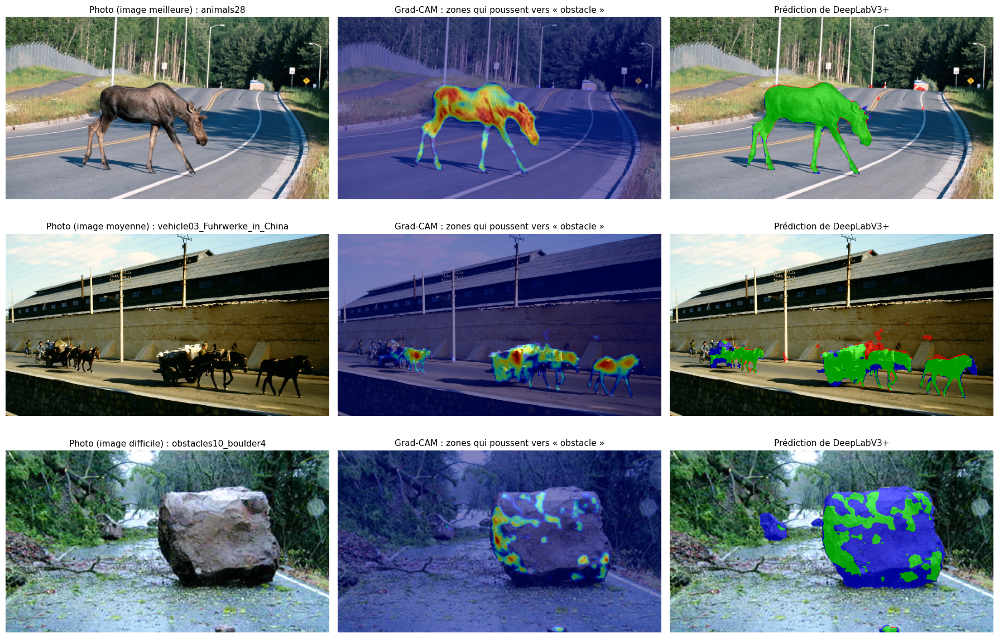

In [75]:
keras.backend.clear_session()
modele_5 = construire_modele_5()[0]
modele_5.load_weights(os.path.join(DOSSIER_MODELES, 'modele_5_deeplabv3plus.weights.h5'))

couches = modele_5.layers
k = max(j for j, c in enumerate(couches) if isinstance(c, layers.Conv2D) and c.filters > 1)
modele_avant = keras.Model(modele_5.inputs, couches[k].output)
couches_apres = couches[k + 1:]

def grad_cam(photo_std):
    activations = modele_avant(tf.constant(photo_std[None]), training=False)
    with tf.GradientTape() as tape:
        tape.watch(activations)
        sortie = activations
        for c in couches_apres:
            sortie = c(sortie)
        cible = tf.reduce_sum(sortie * tf.cast(sortie >= 0.5, tf.float32))
    grads = tape.gradient(cible, activations)
    poids = tf.reduce_mean(grads, axis=(1, 2))
    carte = tf.nn.relu(tf.reduce_sum(activations * poids[:, None, None, :], axis=-1))[0]
    carte = carte / (tf.reduce_max(carte) + 1e-8)
    return tf.image.resize(carte[..., None], (720, 1280))[..., 0].numpy()

fig, axes = plt.subplots(len(choix), 3, figsize=(18, 4 * len(choix)))
for ligne, (rang, i) in enumerate(choix.items()):
    carte = grad_cam(X_test_std[i])
    pred = probas_test['Modèle 5 : DeepLabV3+'][i] >= 0.5
    photo = X_test[i][::2, ::2]
    axes[ligne, 0].imshow(photo)
    axes[ligne, 0].set_title(f"Photo (image {rang}) : {noms_test[i][:35]}", fontsize=11)
    axes[ligne, 1].imshow(photo)
    axes[ligne, 1].imshow(carte[::2, ::2], cmap='jet', alpha=0.5)
    axes[ligne, 1].set_title("Grad-CAM : zones qui poussent vers « obstacle »", fontsize=11)
    axes[ligne, 2].imshow(superposer(photo, pred[::2, ::2], vrai_test[i][::2, ::2]))
    axes[ligne, 2].set_title("Prédiction de DeepLabV3+", fontsize=11)
    for a in axes[ligne]:
        a.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_FIGURES, 'gradcam_deeplabv3plus.png'), dpi=100)
plt.show()
plt.close(fig)

### Étape 32 : classer le type d'obstacle (option, DSO3)

**Objectif :** prédire si l'obstacle de chaque image est un **animal** ou un **autre obstacle**.

**Pourquoi 2 classes :** avec 5 catégories, lost_tires et vehicle n'ont que 3 images chacune ; « animal » / « autre » donne deux groupes équilibrés (31 / 29).

**Méthode :**
- 32a : découper la zone de l'obstacle grâce au masque (rectangle + 10 % de marge), la mettre en 224 × 224, puis extraire ses caractéristiques avec ResNet50 pré-entraîné et gelé (transfer learning).
- 32b : entraîner une seule couche dense (sigmoïde) sur les 40 images d'entraînement ; évaluer sur les 10 images de test (accuracy, F1, matrice de confusion).

**Ce qu'on cherche :** une accuracy nettement au-dessus de 50 % (le hasard).

#### Étape 32a : découper les obstacles et extraire leurs caractéristiques

In [76]:
def recadrer(nom, marge=0.1):
    photo = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.webp')).convert('RGB'))
    masque = np.array(Image.open(os.path.join(FRAMES_DIR, nom + '.labels', 'labels_semantic.png'))) == 2
    lig, col = np.where(masque)
    mh, mw = int(marge * (lig.max() - lig.min() + 1)), int(marge * (col.max() - col.min() + 1))
    h0, h1 = max(0, lig.min() - mh), min(photo.shape[0], lig.max() + mh + 1)
    w0, w1 = max(0, col.min() - mw), min(photo.shape[1], col.max() + mw + 1)
    return np.array(Image.fromarray(photo[h0:h1, w0:w1]).resize((224, 224), Image.BILINEAR))

keras.backend.clear_session()
extracteur = ResNet50(include_top=False, weights='imagenet', pooling='avg', input_shape=(224, 224, 3))
recadrages = np.stack([recadrer(n) for n in df['nom']]).astype(np.float32)
caracteristiques = extracteur.predict(preprocess_input(recadrages.copy()), batch_size=8, verbose=0)
etiquettes = (df['categorie'] == 'animals').astype(int).values
ensembles = df['ensemble'].values

print("Recadrages :", recadrages.shape)
print("Caractéristiques ResNet50 :", caracteristiques.shape)
print("Animaux / autres obstacles :", etiquettes.sum(), "/", len(etiquettes) - etiquettes.sum())

Recadrages : (60, 224, 224, 3)
Caractéristiques ResNet50 : (60, 2048)
Animaux / autres obstacles : 31 / 29


**Conclusions :**
- 60 obstacles découpés et mis en 224 × 224, chacun résumé par ResNet50 en 2 048 caractéristiques.
- Deux groupes équilibrés : 31 animaux, 29 autres obstacles.

#### Étape 32b : entraîner le classifieur et l'évaluer sur le test

In [77]:
tf.random.set_seed(42)
classifieur = keras.Sequential([keras.Input(shape=(2048,)), layers.Dropout(0.5), layers.Dense(1, activation='sigmoid')])
classifieur.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

tr, va, te = ensembles == 'entrainement', ensembles == 'validation', ensembles == 'test'
histo_cls = classifieur.fit(caracteristiques[tr], etiquettes[tr],
                            validation_data=(caracteristiques[va], etiquettes[va]),
                            epochs=100, batch_size=8, verbose=0,
                            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])

pred_te = (classifieur.predict(caracteristiques[te], verbose=0)[:, 0] >= 0.5).astype(int)
noms_classes = {0: 'autre obstacle', 1: 'animal'}
print("Epochs réalisées :", len(histo_cls.history['loss']))
print("Accuracy sur le test :", round((pred_te == etiquettes[te]).mean(), 2), f"({(pred_te == etiquettes[te]).sum()} images sur {te.sum()})")
for classe, nom_classe in noms_classes.items():
    vp = ((pred_te == classe) & (etiquettes[te] == classe)).sum()
    precision = vp / max((pred_te == classe).sum(), 1)
    recall = vp / max((etiquettes[te] == classe).sum(), 1)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    print(f"{nom_classe} : precision {precision:.2f} | recall {recall:.2f} | F1 {f1:.2f}")

pd.crosstab(pd.Series(etiquettes[te], name='vraie classe').map(noms_classes),
            pd.Series(pred_te, name='classe prédite').map(noms_classes))

Epochs réalisées : 48
Accuracy sur le test : 0.9 (9 images sur 10)
autre obstacle : precision 1.00 | recall 0.80 | F1 0.89
animal : precision 0.83 | recall 1.00 | F1 0.91


classe prédite,animal,autre obstacle
vraie classe,,
animal,5,0
autre obstacle,1,4


#### Étape 32c : vérifier les découpages et les prédictions du test
**Objectif :** vérifier à l'œil que chaque découpage montre bien l'obstacle, et voir les prédictions image par image.

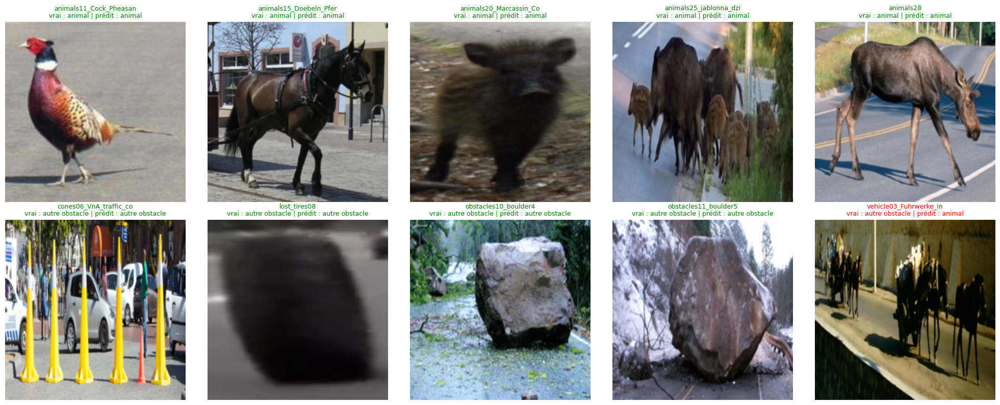

In [80]:
indices_test = np.where(te)[0]
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for a, i, p in zip(axes.ravel(), indices_test, pred_te):
    a.imshow(recadrages[i].astype(np.uint8))
    vraie, predite = noms_classes[etiquettes[i]], noms_classes[p]
    a.set_title(f"{df['nom'].iloc[i][:22]}\nvrai : {vraie} | prédit : {predite}",
                fontsize=9, color='green' if vraie == predite else 'red')
    a.axis('off')
plt.tight_layout()
plt.show()

**Conclusions :**
- Les 10 découpages montrent bien l'obstacle : faisan, cheval, marcassin, sangliers, élan, cônes, pneu, rochers, charrettes.
- Le pneu (0,37 % de l'image) est flou, car son petit rectangle a été agrandi en 224 × 224, mais il est bien classé.
- La seule erreur (vehicle03) montre surtout des chevaux tirant des charrettes : la réponse « animal » est défendable ; c'est l'étiquette « vehicle », tirée du nom de fichier, qui est ambiguë.
- La classification fonctionne bien : 9 images sur 10, sans erreur de découpage.

In [78]:
df.loc[te, 'nom'][pred_te != etiquettes[te]]

59    vehicle03_Fuhrwerke_in_China
Name: nom, dtype: object

- La seule erreur (vehicle03_Fuhrwerke_in_China) est une image de charrettes tirées par des chevaux : étiquetée « vehicle » d'après son nom de fichier, elle contient en fait beaucoup d'animaux. Le modèle n'a pas vraiment tort ; cela montre la limite d'une étiquette unique par image, tirée du nom de fichier.

### Étape 33 : forces, limites et améliorations

**Forces :**
- 5 configurations comparées dans les mêmes conditions, avec deux ablations (augmentation, raccourcis).
- Pleine résolution conservée : aucun petit obstacle perdu.
- Transfer learning décisif : F1 de 0,45 à 0,80 sur le test.
- Évaluation complète : 5 métriques, erreurs (FPR, FNR), recall par taille, visualisations.

**Limites :**
- Peu de données : 60 images, 10 de test, 15 obstacles de test, aucun tout petit.
- Tout petits obstacles (< 0,1 %) mal détectés par les modèles pré-entraînés (22 à 44 %).
- Obstacles camouflés ratés (rocher gris sur route grise).
- Un seul découpage et un seul entraînement par modèle, sans validation croisée.
- Fine-tuning inefficace avec 40 images ; catégories tirées des noms de fichiers.

**Améliorations :**
- Plus de données : Lost and Found, SegmentMeIfYouCan, routes sans obstacle.
- Combiner encodeur pré-entraîné et raccourci en pleine résolution, ou associer U-Net et DeepLabV3+.
- Seuil plus bas que 0,5 pour gagner du recall ; perte focale pour les petits objets.
- Validation croisée et plusieurs entraînements par modèle.
- Autoencoder entraîné sur des routes normales ; Grad-CAM pour expliquer les erreurs.

# 7. Conclusion

- **BO1 (détecter et localiser les obstacles) : atteint.** Meilleur modèle : DeepLabV3+ avec encodeur ResNet50 pré-entraîné. Sur le test : F1 0,80, IoU 0,66, Dice 0,78, recall 0,76, precision 0,83, et seulement 1,6 % du fond signalé à tort.
- **BO2 (obstacles lointains) : atteint en partie.** Les petits obstacles (0,1-1 % de l'image) sont bien détectés par les modèles pré-entraînés (100 % sur le test, 94 % sur la validation), mais les tout petits (< 0,1 %) restent leur point faible (22 à 44 %).
- **DSO3 (option) : atteint.** 90 % d'accuracy pour distinguer animal et autre obstacle.
- **Enseignement principal :** avec 60 images, le pré-entraînement compte bien plus que l'architecture ; la pleine résolution reste nécessaire pour les obstacles les plus lointains.

### Étape 34 : exporter les fichiers de l'interface
**Objectif :** sauvegarder les statistiques de standardisation, la liste des images de test et le classifieur, pour que l'interface Streamlit (`app.py`) puisse les utiliser.

In [81]:
config = {'moyenne': moyenne.tolist(), 'ecart_type': ecart_type.tolist(),
          'images_test': df.loc[df['ensemble'] == 'test', 'nom'].tolist()}
with open(os.path.join(DOSSIER_MODELES, 'config_interface.json'), 'w') as f:
    json.dump(config, f)
classifieur.save_weights(os.path.join(DOSSIER_MODELES, 'classifieur_animal.weights.h5'))
print("Fichiers exportés dans", DOSSIER_MODELES)

Fichiers exportés dans c:\Projet DeepLearning\RoadAnomaly_modeles
